# EDA integrada: dados de mercado, macroeconomia e notícias × Bitcoin

Este notebook reúne a análise exploratória das duas trilhas do projeto (*Market Analysis Driven by Event Studies*):

- **estruturada:** BTC, 9 índices de ações, 7 câmbios, 11 juros e 11 CPIs (2016–2025, HuggingFace);
- **não estruturada:** 79 mil notícias sobre bitcoin do GDELT (Reuters, Bloomberg, CoinDesk, Cointelegraph, 2017–2026).

A pergunta central é **"as notícias ajudam a prever o Bitcoin?"**. Para respondê-la, a EDA segue este roteiro:

| Seção | Pergunta | Hipóteses |
|---|---|---|
| 1. Os dados | A base é confiável e sem vazamento? Como as duas trilhas se alinham? | — |
| 2. Dados estruturados | Como o BTC se comporta? O que é previsível nele? Como ele se relaciona com os mercados? | H1–H4 |
| 3. Notícias | Quem publica, quando, com que tom e sobre quais temas? | H5 |
| 4. Correlações | Com quais variáveis estruturadas as notícias se relacionam, e isso é contemporâneo ou preditivo? | H6 |
| 5–6. Direção | O sentimento antecipa o retorno? (correlação defasada, Granger, estudo de eventos) | H7–H9 |
| 7. Volatilidade | As notícias antecipam a volatilidade além da própria volatilidade passada? | H10 |
| 8. Regimes | A relação é estável no tempo? O tom reflete o estado do mercado? | H11–H12 |
| 9. Temas | Algum tema específico antecipa o preço? | H13 |

Convenções iguais às do `struc_data.ipynb`: α = 0,05, log-retornos e testes não paramétricos quando há caudas pesadas.
A numeração das hipóteses é própria deste notebook; a análise geral completa da base estruturada (estacionariedade,
volume, halvings, Granger com mercados e macro, regimes do Fed) continua no `struc_data.ipynb`.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.multitest import multipletests
from statsmodels.graphics.tsaplots import plot_acf

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

DATA = Path.cwd().parent / "data"
ALPHA = 0.05

# Mesma paleta e tema do struc_data.ipynb
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
GRAY = "#8a8985"
CMAP_DIV = sns.diverging_palette(250, 15, s=75, l=50, center="light", as_cmap=True)
sns.set_theme(style="whitegrid", rc={
    "axes.prop_cycle": plt.cycler(color=C), "axes.edgecolor": "#d6d5d0", "grid.color": "#ecebe7",
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 1.6,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

def veredito(p, h0):
    print(f"   H0: {h0}")
    print(f"   p-valor = {p:.4g} -> {'REJEITA' if p < ALPHA else 'NÃO rejeita'} H0 (α = {ALPHA})")

## 1. Os dados

### 1.1 Correção de vazamento: defasagem de publicação das séries macro

O FRED data cada observação mensal pelo **início do mês de referência**: o CPI de janeiro fica em 01/01, mas o BLS só o
divulga por volta de 10 a 15 de fevereiro. Como a base faz *forward fill* a partir dessa data, o valor do CPI de janeiro
aparecia em 01/01, **cerca de 45 dias antes de existir**. Qualquer modelo treinado assim estaria usando o futuro.

**Correção:** cada série é deslocada pela sua defasagem de publicação (`PUBLICATION_LAGS` em `config.py`), em
`DataProcessing.apply_publication_lag`, aplicada na unificação.

,defasagem (dias)
US_CPI,45
GERMANY_CPI,55
FRANCE_CPI,55
ITALY_CPI,55
UK_CPI,55
JAPAN_CPI,55
CHINA_CPI,55
INDIA_CPI,55
BRAZIL_CPI,55
SOUTH_AFRICA_CPI,55


,valor do CPI,aparece na base antiga em,aparece na base corrigida em
Date,,,
2022-01-01,282.5430,2022-01-01,2022-02-15
2022-02-01,284.5000,2022-02-01,2022-03-18
2022-03-01,287.6740,2022-03-01,2022-04-15
2022-04-01,288.5610,2022-04-01,2022-05-16
2022-05-01,291.2980,2022-05-01,2022-06-15
2022-06-01,294.9570,2022-06-01,2022-07-16
2022-07-01,294.9130,2022-07-01,2022-08-15
2022-08-01,295.0970,2022-08-01,2022-09-15
2022-09-01,296.3490,2022-09-01,2022-10-16


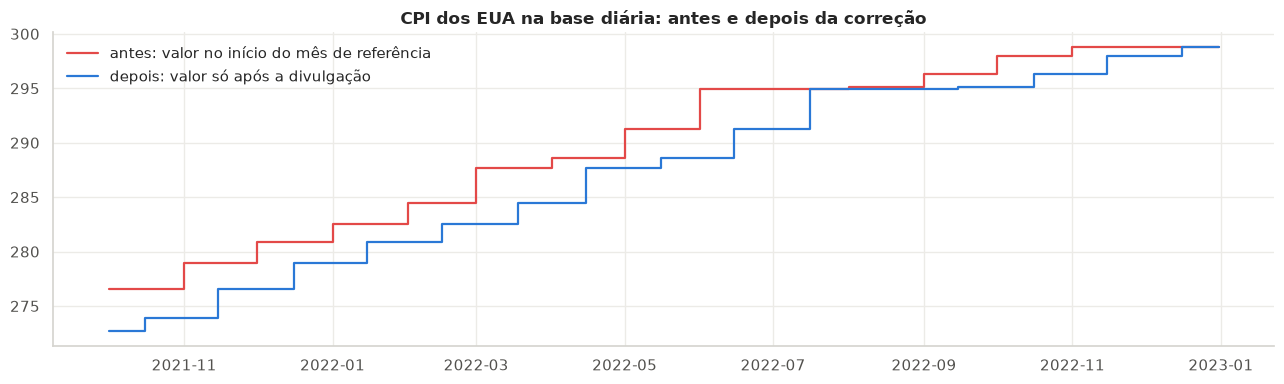

In [2]:
from data_processing.struc_data_processing import DataProcessing
from data_collection.config import PUBLICATION_LAGS

dp = DataProcessing()
raw = dp.load_from_hf_struc(apply_lag=False, save=False)   # versão publicada em 17/09
pit = DataProcessing.apply_publication_lag(raw)                # versão corrigida (point-in-time)

display(pd.Series(PUBLICATION_LAGS, name="defasagem (dias)").to_frame())

# Em que dia cada valor do CPI americano "aparece" na base?
mudou = raw["US_CPI"].diff() != 0
exemplo = pd.DataFrame({
    "valor do CPI": raw.loc[mudou, "US_CPI"],
    "aparece na base antiga em": raw.index[mudou],
}).iloc[1:]
exemplo["aparece na base corrigida em"] = exemplo["aparece na base antiga em"] + pd.Timedelta(days=PUBLICATION_LAGS["US_CPI"])
display(exemplo.loc["2022"])

fig, ax = plt.subplots(figsize=(13, 4))
janela = slice("2021-10-01", "2022-12-31")
ax.step(raw.loc[janela].index, raw.loc[janela, "US_CPI"], where="post", color=C[7], label="antes: valor no início do mês de referência")
ax.step(pit.loc[janela].index, pit.loc[janela, "US_CPI"], where="post", color=C[0], label="depois: valor só após a divulgação")
ax.set_title("CPI dos EUA na base diária: antes e depois da correção")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Leitura:** na base antiga, o CPI de cada mês aparecia no dia 1º desse mês; na corrigida, só depois da divulgação. A
EDA da Entrega 1 não é afetada (ela agregava por mês, olhando relações contemporâneas), mas os modelos de previsão
seriam: o vazamento apareceria como um falso poder preditivo das variáveis de inflação e juros mensais.

> A versão no HuggingFace ainda é a antiga. Ao recoletar com as API keys (`main.py`), `unify_data` já aplica a
> defasagem; depois disso, `load_from_hf_struc(apply_lag=False)` deve ser usado para não defasar duas vezes.

### 1.2 Integração das duas trilhas

**Calendário:** o do BTC (7 dias por semana), como decidido na Entrega 1.
**Fuso:** o candle diário do BTC no yfinance vai de 00h a 24h UTC, e os timestamps do GDELT também estão em UTC. Assim, a
linha do dia *t* contém apenas o que já se sabia às 24h UTC de *t*: o fechamento do BTC, o fechamento de todas as bolsas
(a última a fechar, Nova York, fecha às 20h/21h UTC), as séries macro já divulgadas e as notícias publicadas em *t*.

In [3]:
from data_processing.integration import DataIntegration
df = DataIntegration().run()

cob = df.groupby(df.index.year).agg(dias=("BTC_Close", "size"), dias_com_cobertura=("has_news_coverage", "sum"),
                                    noticias=("news_count", "sum"), dias_sem_noticia=("news_count", lambda s: (s == 0).sum()))
display(cob)

Base integrada salva em '/home/leodemore/GitHub/MADES/MADES/sources/data/integrated_dataframe.csv' | (3650, 74) | notícias de 2017-01-01 a 2026-01-31


,dias,dias_com_cobertura,noticias,dias_sem_noticia
Date,,,,
2016,363,0,0.0000,0
2017,365,365,"9,790.0000",4
2018,365,365,"13,324.0000",0
2019,365,365,"7,423.0000",1
2020,366,366,"7,214.0000",2
2021,365,365,"8,856.0000",1
2022,365,365,"3,617.0000",1
2023,365,365,"10,091.0000",0
2024,366,366,"11,697.0000",0


A base integrada tem 2016–2025 (3.650 dias). As notícias começam em 2017, então 2016 serve só de "aquecimento" para as
features de mercado (médias móveis, volatilidade de 30 dias). No período 2017–2025, apenas 33 dias não têm nenhuma notícia.

Mais abaixo usamos as features construídas em `modeling/features.py` (todas usam informação até *t*). O tom é o
**tom ajustado pela fonte**, ponderado pelo número de notícias.

### 1.3 Grupos de variáveis e frequências de origem

As variáveis da base integrada têm **frequências de origem diferentes**, e isso pesa em toda a análise:

| Grupo | Frequência real | Cuidados |
|---|---|---|
| Bitcoin (OHLCV) | diária, 7 dias por semana | é o calendário da base |
| Índices de ações e câmbio | dias úteis | fim de semana e feriado repetem o último valor: comparações de retorno usam só dias úteis |
| Juros e inflação (CPI) | mensal ou por decisão de política | já defasados pela data de divulgação (1.1); analisados em frequência mensal |
| Notícias (GDELT) | contínua (resolução de 15 min), agregada por dia UTC | começam em 2017; 2016 serve de aquecimento para as features de mercado |

In [4]:
from modeling.features import INDICES, FX, RATES, CPIS

grupos = {
    "Bitcoin": [c for c in df.columns if c.startswith("BTC_")],
    "Índices de ações": INDICES,
    "Câmbio": FX,
    "Juros": ["US_FEDFUNDS"] + RATES,
    "Inflação (CPI)": CPIS,
    "Notícias (agregado)": [c for c in df.columns if c.startswith("news_")],
    "Notícias por tema": [c for c in df.columns if c.startswith("clu")],
}
cobertura = df["has_news_coverage"] == 1
linhas = []
for g, cols in grupos.items():
    base = df.loc[cobertura, cols] if g.startswith("Notícias") else df[cols]
    linhas.append({"grupo": g, "variáveis": len(cols),
                   "% nulos": base.isna().mean().mean() * 100,
                   # fração de dias em que o valor não muda: revela a frequência real da série
                   "% dias sem variação (mediana)": ((base.diff().iloc[1:] == 0).mean() * 100).median()})
display(pd.DataFrame(linhas).set_index("grupo").round(1))
print("Datas duplicadas:", df.index.duplicated().sum(), "| intervalos entre datas:",
      df.index.to_series().diff().value_counts().to_dict())

,variáveis,% nulos,% dias sem variação (mediana)
grupo,,,
Bitcoin,5,0.0000,0.0000
Índices de ações,9,0.0000,31.1000
Câmbio,7,0.0000,28.9000
Juros,11,0.4000,97.7000
Inflação (CPI),11,1.5000,95.8000
Notícias (agregado),8,0.6000,0.5000
Notícias por tema,22,0.0000,5.9000


Datas duplicadas: 0 | intervalos entre datas: {Timedelta('1 days 00:00:00'): 3649}


**Leitura:** o calendário é contínuo (sem datas repetidas nem buracos). Nos índices e câmbios, cerca de 30% dos dias não
têm variação (fins de semana e feriados). Juros e CPI mudam em menos de 5% dos dias, então correlações **diárias** com
eles seriam dominadas por valores repetidos. Os poucos nulos de juros e CPI estão no início da série: são a janela
aberta pela defasagem de publicação. Nas notícias, os nulos são as médias de tom dos 33 dias sem nenhuma notícia; as
contagens desses dias são 0.

In [5]:
from modeling.features import build_dataset
N_CLUSTERS = int(pd.read_csv(DATA / "news_clusters.csv")["cluster"].max())
data, groups = build_dataset(df, N_CLUSTERS)
r = data["btc_ret_1d"]
print(f"Base de análise: {data.index.min().date()} a {data.index.max().date()} | {data.shape}")
print({g: len(c) for g, c in groups.items()})

Base de análise: 2017-02-01 a 2025-12-31 | (3256, 136)
{'btc': 17, 'mercado_macro': 60, 'noticias': 44, 'mercado_vol': 6, 'noticias_atencao': 4}


## 2. Dados estruturados: o que o Bitcoin e os mercados mostram

Esta seção traz do `struc_data.ipynb` os resultados necessários para entender o problema de previsão: como o BTC se
comporta, o que nele é previsível e como ele se relaciona com os mercados tradicionais. Os dados são os da base
integrada (já com a defasagem de publicação), no período completo de 2016 a 2025.

### 2.1 Preço, risco e retornos

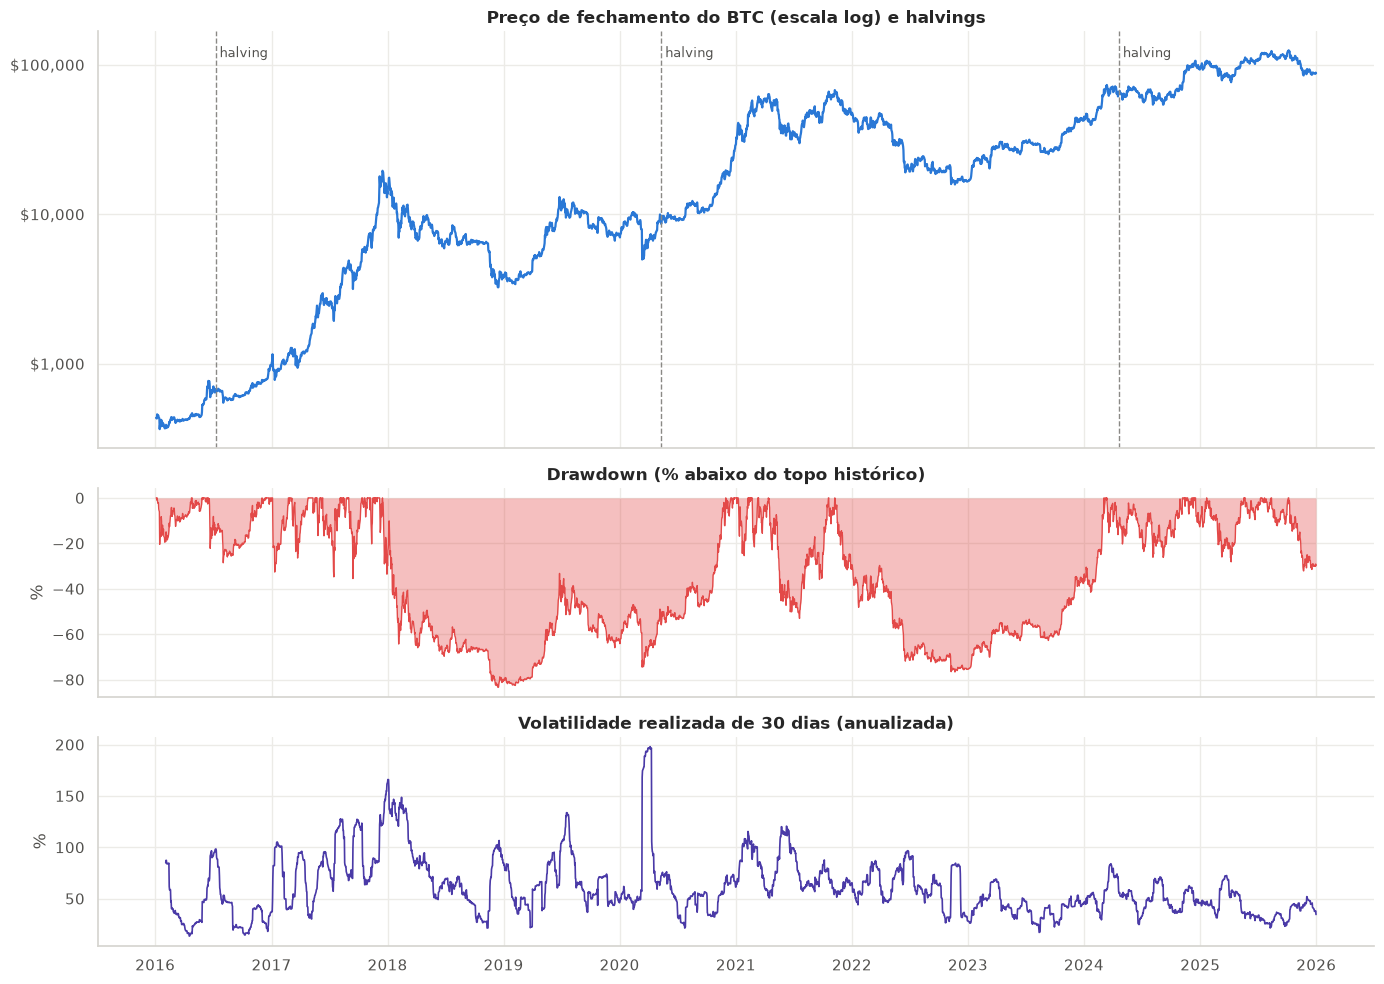

Retorno total no período: 20,105.6%
Retorno anualizado (CAGR): 70.1%
Volatilidade anualizada: 67.5%
Máximo drawdown: -83.4% em 2018-12-15


Date,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
retorno (%),122.5000,"1,368.9000",-73.6000,92.2000,303.2000,59.7000,-64.3000,155.4000,121.1000,-6.3000
volatilidade anualizada (%),48.5000,94.2000,82.0000,67.5000,76.6000,80.3000,64.2000,43.3000,53.1000,41.9000
max drawdown no ano (%),-28.6000,-35.5000,-81.5000,-49.0000,-51.9000,-53.1000,-66.9000,-20.1000,-26.2000,-32.1000


In [6]:
btc = df["BTC_Close"]
rb = np.log(btc).diff().dropna()        # log-retorno diário no período inteiro (2016-2025)
dd = btc / btc.cummax() - 1             # drawdown em relação ao topo histórico
vol30 = rb.rolling(30).std() * np.sqrt(365)
HALVINGS = pd.to_datetime(["2016-07-09", "2020-05-11", "2024-04-20"])

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True, gridspec_kw={"height_ratios": [2, 1, 1]})
axes[0].plot(btc.index, btc, color=C[0])
axes[0].set_yscale("log")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
axes[0].set_title("Preço de fechamento do BTC (escala log) e halvings")
for h in HALVINGS:
    axes[0].axvline(h, color=GRAY, ls="--", lw=1)
    axes[0].text(h, btc.max() * 0.9, " halving", color="#52514e", fontsize=9)
axes[1].fill_between(dd.index, dd * 100, 0, color=C[7], alpha=0.35, lw=0)
axes[1].plot(dd.index, dd * 100, color=C[7], lw=1)
axes[1].set_title("Drawdown (% abaixo do topo histórico)")
axes[1].set_ylabel("%")
axes[2].plot(vol30.index, vol30 * 100, color=C[6], lw=1.2)
axes[2].set_title("Volatilidade realizada de 30 dias (anualizada)")
axes[2].set_ylabel("%")
axes[2].xaxis.set_major_locator(mdates.YearLocator())
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.show()

print(f"Retorno total no período: {btc.iloc[-1] / btc.iloc[0] - 1:,.1%}")
print(f"Retorno anualizado (CAGR): {(btc.iloc[-1] / btc.iloc[0]) ** (365 / (len(btc) - 1)) - 1:.1%}")
print(f"Volatilidade anualizada: {rb.std() * np.sqrt(365):.1%}")
print(f"Máximo drawdown: {dd.min():.1%} em {dd.idxmin().date()}")

ano = btc.index.year
fim_ano = btc.groupby(ano).last()
# base de cada ano = fechamento do ano anterior (2016: primeiro preço disponível)
ini_ano = pd.concat([pd.Series([btc.iloc[0]], index=fim_ano.index[:1]), fim_ano.iloc[:-1].set_axis(fim_ano.index[1:])])
anual = pd.DataFrame({
    "retorno (%)": (fim_ano / ini_ano - 1) * 100,
    "volatilidade anualizada (%)": rb.groupby(rb.index.year).std() * np.sqrt(365) * 100,
    "max drawdown no ano (%)": btc.groupby(ano).apply(lambda s: (s / s.cummax() - 1).min()) * 100,
})
display(anual.round(1).T)

**Leitura:** o BTC valorizou cerca de **200 vezes** em 10 anos (CAGR ≈ 70% a.a.), com volatilidade anualizada de ≈ 68%
e dois drawdowns acima de 75% (2018 e 2022). A volatilidade **diminui ao longo do tempo**: ficou entre 68% e 94% a.a. em
2017–2021 e entre 42% e 53% a.a. em 2023–2025, um mercado maior e mais maduro. Isso importa para a modelagem: um modelo
treinado nos anos turbulentos superestima o risco recente.

#### H1. Os retornos diários do BTC seguem uma distribuição normal?

- **H0:** os log-retornos diários são normalmente distribuídos.
- **Testes:** Jarque-Bera (assimetria e curtose) e Kolmogorov-Smirnov contra a normal padronizada.

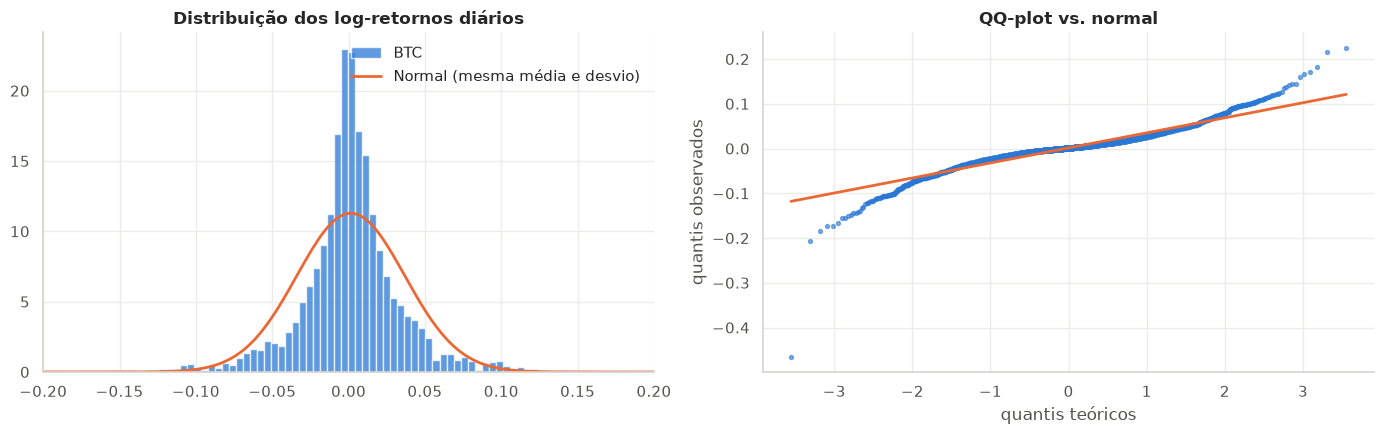

Assimetria: -0.667 | Curtose em excesso: 12.23 (normal = 0)
Dias com |retorno| > 3 desvios: 64 (esperado numa normal: 10)

Jarque-Bera
   H0: retornos normais
   p-valor = 0 -> REJEITA H0 (α = 0.05)
Kolmogorov-Smirnov
   H0: retornos normais
   p-valor = 1.323e-31 -> REJEITA H0 (α = 0.05)


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.linspace(rb.min(), rb.max(), 400)
axes[0].hist(rb, bins=150, density=True, color=C[0], alpha=0.75, label="BTC")
axes[0].plot(x, stats.norm.pdf(x, rb.mean(), rb.std()), color=C[1], lw=2, label="Normal (mesma média e desvio)")
axes[0].set_xlim(-0.2, 0.2)
axes[0].set_title("Distribuição dos log-retornos diários")
axes[0].legend(frameon=False)
(osm, osr), (slope, intercept, _) = stats.probplot(rb, dist="norm")
axes[1].scatter(osm, osr, s=8, color=C[0], alpha=0.6)
axes[1].plot(osm, slope * osm + intercept, color=C[1], lw=2)
axes[1].set_title("QQ-plot vs. normal")
axes[1].set_xlabel("quantis teóricos")
axes[1].set_ylabel("quantis observados")
plt.tight_layout()
plt.show()

print(f"Assimetria: {stats.skew(rb):.3f} | Curtose em excesso: {stats.kurtosis(rb):.2f} (normal = 0)")
z = (rb - rb.mean()) / rb.std()
print(f"Dias com |retorno| > 3 desvios: {(z.abs() > 3).sum()} (esperado numa normal: {len(rb) * 2 * stats.norm.sf(3):.0f})")
print("\nJarque-Bera"); veredito(stats.jarque_bera(rb).pvalue, "retornos normais")
print("Kolmogorov-Smirnov"); veredito(stats.kstest(z, "norm").pvalue, "retornos normais")

**Conclusão H1:** a normalidade é rejeitada com folga. A distribuição tem **caudas muito pesadas** (curtose em excesso
≈ 12) e leve **assimetria negativa**: quedas extremas são mais violentas que altas extremas. Houve 64 dias com
movimentos maiores que 3 desvios-padrão, contra cerca de 10 esperados numa normal. Por isso preferimos testes não
paramétricos (Spearman, Kruskal-Wallis, Wilcoxon e placebo no estudo de eventos) no resto do notebook.

#### H2. Os retornos são previsíveis pelo passado? Há clusters de volatilidade?

- **Ljung-Box em $r_t$:** H0 = não há autocorrelação nos retornos (eficiência fraca).
- **Ljung-Box em $r_t^2$ e teste ARCH-LM:** H0 = não há heterocedasticidade condicional, ou seja, a volatilidade não se agrupa.

Esta hipótese define o que é realista esperar das notícias: se nem o passado do próprio preço prevê a direção, a
barra para uma variável externa é alta.

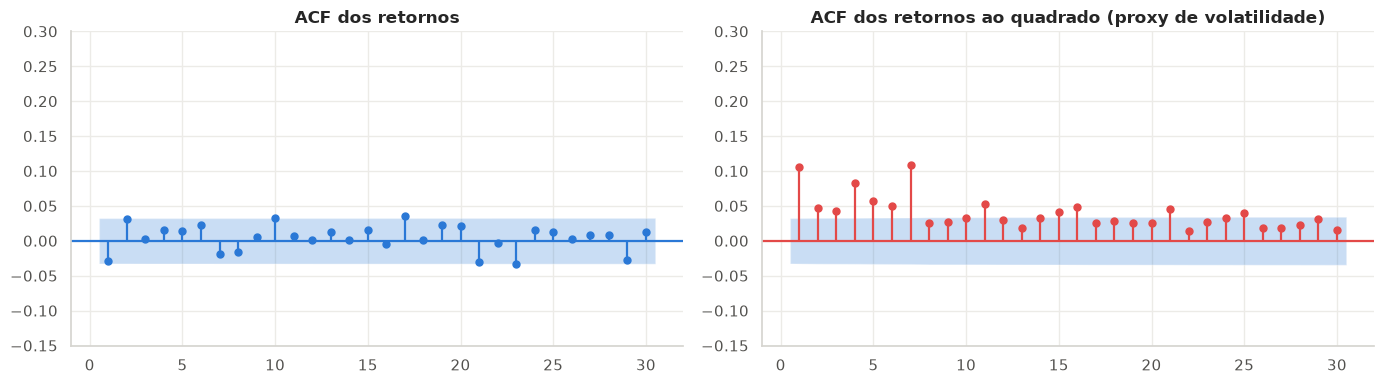

Ljung-Box (10 lags) em r
   H0: sem autocorrelação nos retornos
   p-valor = 0.08794 -> NÃO rejeita H0 (α = 0.05)
Ljung-Box (10 lags) em r²
   H0: sem autocorrelação na volatilidade
   p-valor = 8.368e-28 -> REJEITA H0 (α = 0.05)
ARCH-LM
   H0: sem efeito ARCH
   p-valor = 2.219e-19 -> REJEITA H0 (α = 0.05)


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(rb, lags=30, ax=axes[0], zero=False, color=C[0], vlines_kwargs={"colors": C[0]})
axes[0].set_title("ACF dos retornos")
plot_acf(rb ** 2, lags=30, ax=axes[1], zero=False, color=C[7], vlines_kwargs={"colors": C[7]})
axes[1].set_title("ACF dos retornos ao quadrado (proxy de volatilidade)")
for ax in axes:
    ax.set_ylim(-0.15, 0.3)
plt.tight_layout()
plt.show()

print("Ljung-Box (10 lags) em r"); veredito(acorr_ljungbox(rb, lags=[10])["lb_pvalue"].iloc[0], "sem autocorrelação nos retornos")
print("Ljung-Box (10 lags) em r²"); veredito(acorr_ljungbox(rb ** 2, lags=[10])["lb_pvalue"].iloc[0], "sem autocorrelação na volatilidade")
print("ARCH-LM"); veredito(het_arch(rb)[1], "sem efeito ARCH")

**Conclusão H2:** os **retornos** praticamente não têm memória linear (não se rejeita H0 a 5%): o retorno de ontem não
prevê o de hoje. Já os **retornos ao quadrado** são fortemente autocorrelacionados e o teste ARCH é significativo: há
**clusters de volatilidade**. A **volatilidade** é bem mais previsível que a **direção**, e esse é o pano de fundo
para as notícias. Elas só ajudam se trouxerem informação que o passado do preço ainda não tem: na direção, onde quase
nada é previsível, e na volatilidade, onde a própria volatilidade passada já explica muito (H10).

#### H3. Existe sazonalidade nos retornos? A volatilidade é menor nos fins de semana?

- **Kruskal-Wallis:** H0 = a distribuição dos retornos é a mesma em todos os dias da semana (e em todos os meses).
- **Levene:** H0 = a variância dos retornos no fim de semana é igual à dos dias úteis.

O ciclo semanal importa para a parte de notícias: ele aparece de novo no volume de notícias (seção 3) e explica alguns
picos de correlação na seção 5.

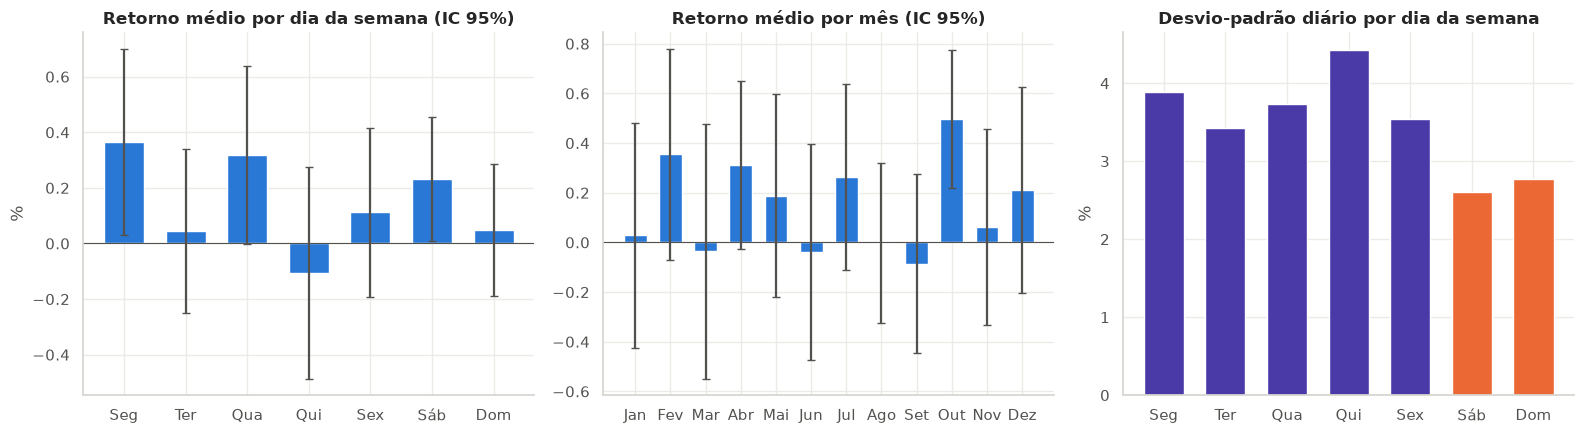

Kruskal-Wallis: dia da semana
   H0: mesma distribuição em todos os dias
   p-valor = 0.4872 -> NÃO rejeita H0 (α = 0.05)
Kruskal-Wallis: mês
   H0: mesma distribuição em todos os meses
   p-valor = 0.8919 -> NÃO rejeita H0 (α = 0.05)
Levene: fim de semana (σ = 2.69%) vs. dias úteis (σ = 3.82%)
   H0: variâncias iguais
   p-valor = 8.678e-18 -> REJEITA H0 (α = 0.05)


In [9]:
dias = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
tab = pd.DataFrame({"r": rb * 100, "dia": pd.Categorical([dias[d] for d in rb.index.dayofweek], dias),
                    "mes": pd.Categorical([meses[k - 1] for k in rb.index.month], meses)})

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
por_dia = tab.groupby("dia", observed=True)["r"]
axes[0].bar(dias, por_dia.mean(), color=C[0], width=0.65)
axes[0].errorbar(dias, por_dia.mean(), yerr=1.96 * por_dia.sem(), fmt="none", ecolor="#52514e", capsize=3)
axes[0].axhline(0, color="#52514e", lw=0.8)
axes[0].set_title("Retorno médio por dia da semana (IC 95%)")
axes[0].set_ylabel("%")
por_mes = tab.groupby("mes", observed=True)["r"]
axes[1].bar(meses, por_mes.mean(), color=C[0], width=0.65)
axes[1].errorbar(meses, por_mes.mean(), yerr=1.96 * por_mes.sem(), fmt="none", ecolor="#52514e", capsize=3)
axes[1].axhline(0, color="#52514e", lw=0.8)
axes[1].set_title("Retorno médio por mês (IC 95%)")
axes[2].bar(dias, por_dia.std(), color=[C[6]] * 5 + [C[1]] * 2, width=0.65)
axes[2].set_title("Desvio-padrão diário por dia da semana")
axes[2].set_ylabel("%")
plt.tight_layout()
plt.show()

print("Kruskal-Wallis: dia da semana")
veredito(stats.kruskal(*[g for _, g in por_dia]).pvalue, "mesma distribuição em todos os dias")
print("Kruskal-Wallis: mês")
veredito(stats.kruskal(*[g for _, g in por_mes]).pvalue, "mesma distribuição em todos os meses")
fds = rb.index.dayofweek >= 5
print(f"Levene: fim de semana (σ = {rb[fds].std():.2%}) vs. dias úteis (σ = {rb[~fds].std():.2%})")
veredito(stats.levene(rb[fds], rb[~fds]).pvalue, "variâncias iguais")

**Conclusão H3:** não há sazonalidade no **retorno médio** (nem por dia da semana nem por mês), mas a **volatilidade é
significativamente menor nos fins de semana** (σ de 2,7% contra 3,8% nos dias úteis), quando os mercados tradicionais
estão fechados. O mesmo ciclo aparece no volume de notícias (seção 3).

### 2.2 BTC vs. mercados globais

#### H4. A correlação do BTC com os mercados de risco aumentou a partir de 2020?

- **H0:** a correlação entre os retornos diários do BTC e de cada ativo é a mesma antes (2016–2019) e depois (2020–2025)
  de jan/2020 (z de Fisher). Somente dias úteis.

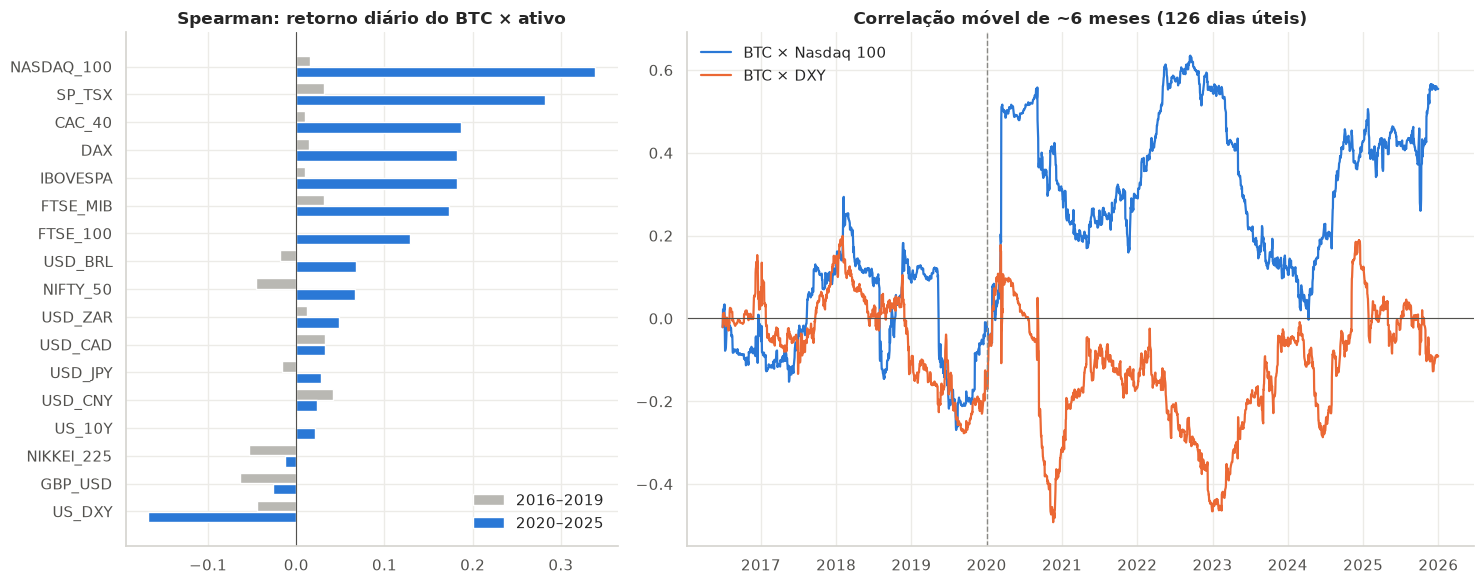

,corr 2016-19,corr 2020-25,z,p_valor,rejeita H0
ativo,,,,,
NASDAQ_100,0.0241,0.3946,9.8169,0.0000,True
US_DXY,-0.0239,-0.1393,-2.9059,0.0037,True
IBOVESPA,0.0398,0.2843,6.3060,0.0000,True
DAX,0.0002,0.2747,7.0363,0.0000,True


In [10]:
uteis = df[df.index.dayofweek < 5]
ret_d = np.log(uteis[["BTC_Close"] + INDICES + FX]).diff()
ret_d["US_10Y"] = uteis["US_10Y"].diff()   # taxa: usa variação absoluta, não log
ret_d = ret_d.dropna()

def fisher_z(r1, n1, r2, n2):
    z = (np.arctanh(r2) - np.arctanh(r1)) / np.sqrt(1 / (n1 - 3) + 1 / (n2 - 3))
    return z, 2 * stats.norm.sf(abs(z))

pre, pos = ret_d[ret_d.index < "2020-01-01"], ret_d[ret_d.index >= "2020-01-01"]
ativos = ret_d.columns.drop("BTC_Close")
comp_reg = pd.DataFrame({
    "2016-19": [stats.spearmanr(pre["BTC_Close"], pre[a])[0] for a in ativos],
    "2020-25": [stats.spearmanr(pos["BTC_Close"], pos[a])[0] for a in ativos],
}, index=ativos).sort_values("2020-25")

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.6]})
y = np.arange(len(comp_reg))
axes[0].barh(y + 0.2, comp_reg["2016-19"], height=0.38, color="#b9b8b3", label="2016–2019")
axes[0].barh(y - 0.2, comp_reg["2020-25"], height=0.38, color=C[0], label="2020–2025")
axes[0].set_yticks(y, comp_reg.index)
axes[0].axvline(0, color="#52514e", lw=0.8)
axes[0].set_title("Spearman: retorno diário do BTC × ativo")
axes[0].legend(frameon=False, loc="lower right")

roll = pd.DataFrame({a: ret_d["BTC_Close"].rolling(126).corr(ret_d[a]) for a in ["NASDAQ_100", "US_DXY"]})
axes[1].plot(roll.index, roll["NASDAQ_100"], color=C[0], label="BTC × Nasdaq 100")
axes[1].plot(roll.index, roll["US_DXY"], color=C[1], label="BTC × DXY")
axes[1].axhline(0, color="#52514e", lw=0.8)
axes[1].axvline(pd.Timestamp("2020-01-01"), color=GRAY, ls="--", lw=1)
axes[1].set_title("Correlação móvel de ~6 meses (126 dias úteis)")
axes[1].legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

linhas = []
for ativo in ["NASDAQ_100", "US_DXY", "IBOVESPA", "DAX"]:
    r1, r2 = pre["BTC_Close"].corr(pre[ativo]), pos["BTC_Close"].corr(pos[ativo])
    zst, p = fisher_z(r1, len(pre), r2, len(pos))
    linhas.append({"ativo": ativo, "corr 2016-19": r1, "corr 2020-25": r2, "z": zst, "p_valor": p, "rejeita H0": p < ALPHA})
display(pd.DataFrame(linhas).set_index("ativo"))

**Conclusão H4:** rejeita-se H0. Antes de 2020, o BTC era praticamente **descorrelacionado** de tudo (|ρ| < 0,06). A
partir de 2020, ele passa a andar com **todos os índices de ações** (Nasdaq ≈ 0,39, S&P/TSX, DAX e Ibovespa ≈ 0,28)
e inversamente ao **dólar** (DXY ≈ −0,14), com pico no aperto monetário de 2022. O BTC passou a se comportar como um
**ativo de risco ligado à liquidez global**. Para a EDA das notícias, isso traz duas consequências: (1) 2020 é uma
**quebra de regime** que precisa ser checada também na relação com as notícias (H11); (2) parte do que move o BTC
depois de 2020 é o apetite global por risco, que não aparece em notícias sobre *bitcoin*.

#### Armadilha: correlação em nível vs. em variação

Juros e inflação são mensais, então aqui os dados são agregados pelo **último valor de cada mês** (já com a defasagem
de publicação). Os níveis de preço são não estacionários (ADF/KPSS no `struc_data.ipynb`), e correlações entre
séries com tendência são em grande parte espúrias.

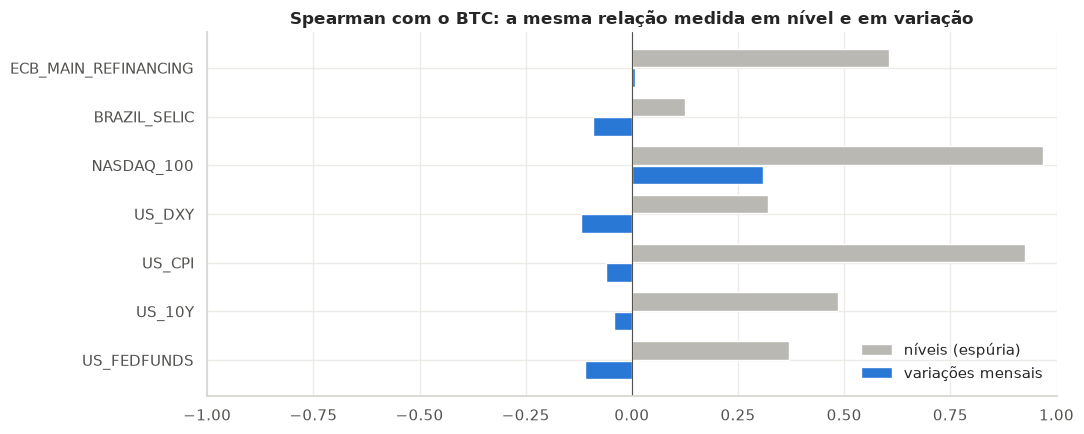

,em nível,em variação
US_FEDFUNDS,0.3704,-0.1105
US_10Y,0.4846,-0.0418
US_CPI,0.9252,-0.0616
US_DXY,0.3204,-0.1187
NASDAQ_100,0.9675,0.3079
BRAZIL_SELIC,0.1242,-0.0919
ECB_MAIN_REFINANCING,0.6066,0.0068


In [11]:
m = df[[c for g in ["Bitcoin", "Índices de ações", "Câmbio", "Juros", "Inflação (CPI)"] for c in grupos[g]]].resample("ME").last()
vars_macro = ["US_FEDFUNDS", "US_10Y", "US_CPI", "US_DXY", "NASDAQ_100", "BRAZIL_SELIC", "ECB_MAIN_REFINANCING"]
nivel = m[["BTC_Close"] + vars_macro].corr(method="spearman")["BTC_Close"].drop("BTC_Close")

mr = pd.DataFrame({"BTC": np.log(m["BTC_Close"]).diff()})
for c in ["US_FEDFUNDS", "US_10Y", "BRAZIL_SELIC", "ECB_MAIN_REFINANCING"]:
    mr[c] = m[c].diff()                         # juros: variação em p.p.
for c in ["US_CPI", "US_DXY", "NASDAQ_100"]:
    mr[c] = np.log(m[c]).diff()                  # níveis de preço: variação %
mr = mr.dropna()
variacao = mr.corr(method="spearman")["BTC"].reindex(vars_macro)
comp = pd.DataFrame({"em nível": nivel, "em variação": variacao})

fig, ax = plt.subplots(figsize=(11, 4.5))
y = np.arange(len(comp))
ax.barh(y + 0.2, comp["em nível"], height=0.38, color="#b9b8b3", label="níveis (espúria)")
ax.barh(y - 0.2, comp["em variação"], height=0.38, color=C[0], label="variações mensais")
ax.set_yticks(y, comp.index)
ax.axvline(0, color="#52514e", lw=0.8)
ax.set_xlim(-1, 1)
ax.set_title("Spearman com o BTC: a mesma relação medida em nível e em variação")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()
display(comp)

**Leitura:** em nível, o BTC parece ter correlação de ≈ 0,93 com o CPI americano e positiva com os juros, mas só porque
**todas essas séries sobem com o tempo**. Em variações mensais, quase tudo desaparece; só a Nasdaq continua relevante
(≈ 0,31). A mesma armadilha vale para as notícias: o **número** de notícias tem tendências e quebras causadas pela
coleta (seção 3), então ele é comparado ao BTC em variações ou em z-score, e não em nível.

## 3. Notícias: quem publica, quando, com que tom e sobre o quê

Antes de cruzar as notícias com o preço, é preciso entender a série em si: uma mudança na **cobertura** (mais ou menos
fontes coletadas) pode parecer uma mudança na **atenção** da mídia, e uma mudança na **composição** de fontes pode
parecer uma mudança no **sentimento**.

### 3.1 Volume e composição das fontes

Notícias únicas: 79,186 | 2017-01-01 a 2026-01-31
Fora das visões por fonte (< 100 notícias): {'theblock.co': 1}


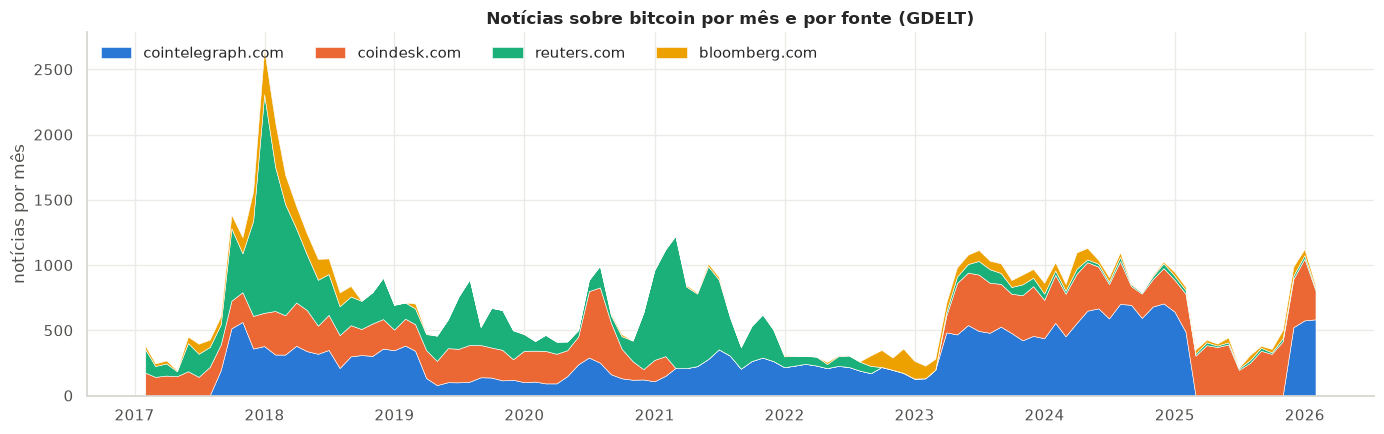

Date,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Source,,,,,,,,,,
cointelegraph.com,2012,3850,1866,1871,2979,2441,5124,7499,1590,584
coindesk.com,2309,3089,2718,3218,151,0,3390,3408,4112,222
reuters.com,4348,5018,2782,2089,5640,521,685,303,239,15
bloomberg.com,1121,1367,57,36,86,655,892,486,390,22
total,9790,13324,7423,7214,8856,3617,10091,11696,6331,843


Participação de cada fonte no ano (%):


Date,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Source,,,,,,,,,,
cointelegraph.com,20.6000,28.9000,25.1000,25.9000,33.6000,67.5000,50.8000,64.1000,25.1000,69.3000
coindesk.com,23.6000,23.2000,36.6000,44.6000,1.7000,0.0000,33.6000,29.1000,65.0000,26.3000
reuters.com,44.4000,37.7000,37.5000,29.0000,63.7000,14.4000,6.8000,2.6000,3.8000,1.8000
bloomberg.com,11.5000,10.3000,0.8000,0.5000,1.0000,18.1000,8.8000,4.2000,6.2000,2.6000


In [12]:
from data_processing.nlp_processing import NewsProcessing
news = NewsProcessing().load_news()
contagem = news["Source"].value_counts()
# theblock.co tem uma única notícia na base: fica fora das visões por fonte
FONTES = contagem[contagem >= 100].index.tolist()
print("Fora das visões por fonte (< 100 notícias):", contagem[contagem < 100].to_dict())

mensal = news.groupby([pd.Grouper(key="Date", freq="ME"), "Source"]).size().unstack(fill_value=0)[FONTES]
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.stackplot(mensal.index, mensal.T.values, labels=FONTES, colors=C[:len(FONTES)], edgecolor="white", linewidth=0.4)
ax.set_title("Notícias sobre bitcoin por mês e por fonte (GDELT)")
ax.set_ylabel("notícias por mês")
ax.legend(frameon=False, ncol=len(FONTES), loc="upper left")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.show()

por_ano = pd.crosstab(news["Date"].dt.year, news["Source"])[FONTES]
display(por_ano.assign(total=por_ano.sum(axis=1)).T)
print("Participação de cada fonte no ano (%):")
display((por_ano.div(por_ano.sum(axis=1), axis=0) * 100).round(1).T)

**Leitura:** o volume de notícias **não é homogêneo no tempo**, e grande parte da variação vem da **coleta**, e não da
atenção da mídia:

- o pico de **dez/2017–fev/2018** (até 2.651 notícias por mês) é real: é a bolha de 2017;
- a **CoinDesk some** de fev/2021 a fev/2023 (25 meses com zero notícias), a **Reuters cai a zero** entre set/2022 e
  fev/2023 e a **Cointelegraph some** de fev a out/2025. São buracos da indexação do GDELT, e não dias sem notícias;
- a composição muda muito: a Reuters respondia por 44% das notícias em 2017 e 64% em 2021, mas por menos de 4% em
  2024–2025.

**Implicações:** o *nível* do número de notícias não é comparável entre anos. Por isso as features de atenção usam o
**z-score em relação aos 30 dias anteriores** (`news_count_z30`), que se adapta a cada patamar de cobertura. Quedas
bruscas de volume (2022, 2025) devem ser lidas como mudança de cobertura, e não como desinteresse da mídia.

#### H5. O tom de base difere entre as fontes?

O tom do GDELT (`SentimentScore`) é calculado por dicionário: varia de −100 a +100, mas na prática fica entre −10 e +10.
Se cada veículo tem um "estilo" diferente, a mudança na composição de fontes vista acima mudaria o tom médio sem que
o sentimento real tivesse mudado.

- **H0:** a distribuição do tom é a mesma nas 5 fontes (Kruskal-Wallis), para o tom bruto e para o ajustado pela fonte.

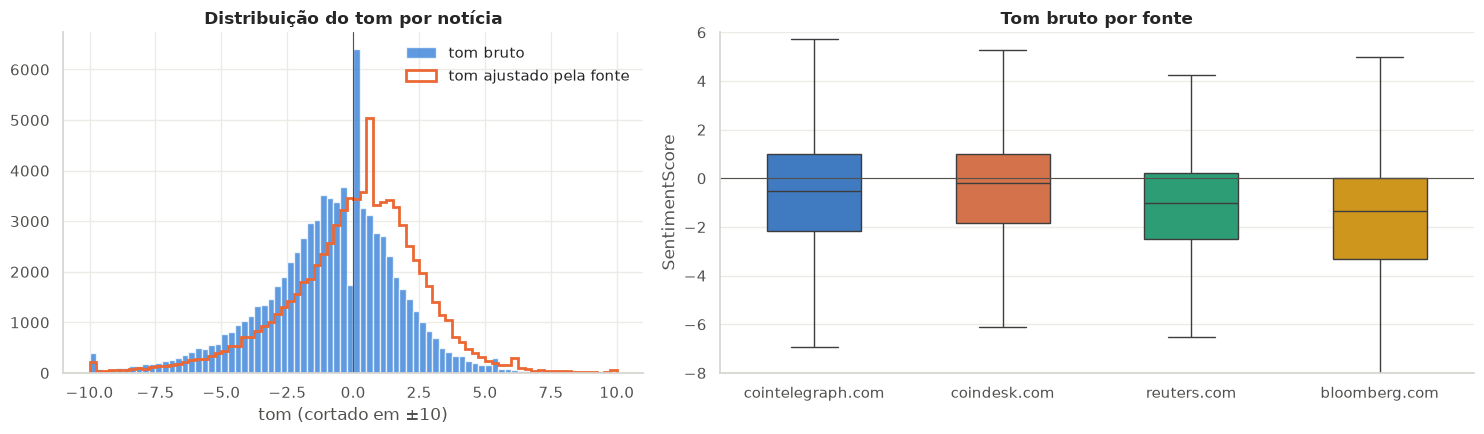

SentimentScore                ToneAdj              
                            mean  median    std    mean median    std
Source                                                               
cointelegraph.com        -0.7200 -0.5200 2.7200 -0.0400 0.1600 2.7200
coindesk.com             -0.5200 -0.2000 2.6100  0.0500 0.3600 2.6100
reuters.com              -1.3000 -1.0300 2.3500  0.3200 0.5800 2.3200
bloomberg.com            -1.7000 -1.3500 3.1500 -0.1600 0.1600 3.1400

% de notícias com tom < 0: 59.0%

Kruskal-Wallis, tom bruto: ε² = 0.0220
   H0: mesmo tom bruto em todas as fontes
   p-valor = 0 -> REJEITA H0 (α = 0.05)

Kruskal-Wallis, tom ajustado: ε² = 0.0047
   H0: mesmo tom ajustado em todas as fontes
   p-valor = 1.568e-79 -> REJEITA H0 (α = 0.05)


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 1.3]})
bins = np.linspace(-10, 10, 81)
axes[0].hist(news["SentimentScore"].clip(-10, 10), bins=bins, color=C[0], alpha=0.75, label="tom bruto")
axes[0].hist(news["ToneAdj"].clip(-10, 10), bins=bins, histtype="step", color=C[1], lw=2, label="tom ajustado pela fonte")
axes[0].axvline(0, color="#52514e", lw=0.8)
axes[0].set_title("Distribuição do tom por notícia")
axes[0].set_xlabel("tom (cortado em ±10)")
axes[0].legend(frameon=False)

sns.boxplot(data=news, x="Source", y="SentimentScore", order=FONTES, palette=C[:len(FONTES)], width=0.5,
            fliersize=0, linewidth=1, ax=axes[1])
axes[1].axhline(0, color="#52514e", lw=0.8)
axes[1].set_ylim(-8, 6)
axes[1].set_title("Tom bruto por fonte")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

display(news.groupby("Source")[["SentimentScore", "ToneAdj"]].agg(["mean", "median", "std"]).loc[FONTES].round(2))
print(f"% de notícias com tom < 0: {(news['SentimentScore'] < 0).mean():.1%}")
# Com ~79 mil notícias qualquer diferença vira "significativa"; o ε² (fração da variância dos postos
# explicada pela fonte) mostra se a diferença é grande
nf = news[news["Source"].isin(FONTES)]
for col, nome in [("SentimentScore", "tom bruto"), ("ToneAdj", "tom ajustado")]:
    kw = stats.kruskal(*[g[col] for _, g in nf.groupby("Source")])
    print(f"\nKruskal-Wallis, {nome}: ε² = {kw.statistic / (len(nf) - 1):.4f}")
    veredito(kw.pvalue, f"mesmo {nome} em todas as fontes")

**Conclusão H5:** rejeita-se H0. O tom de base varia bastante entre as fontes: **Bloomberg (−1,7) e Reuters (−1,3)** são
bem mais negativas que **Cointelegraph (−0,7) e CoinDesk (−0,5)**, e 59% das notícias têm tom negativo. Como a
composição de fontes muda ao longo dos anos (3.1), o tom bruto mistura sentimento com "quem estava sendo coletado".
O **ajuste pela média histórica de cada fonte** reduz o efeito da fonte em cerca de 80% (ε² de 0,022 para 0,005).
A diferença que resta é estatisticamente significativa só por causa do tamanho da amostra (n ≈ 79 mil) e é pequena na
prática. Ela vem principalmente da Reuters (tom ajustado médio de +0,32), porque a média histórica é calculada só com o
passado e demora a convergir no início da série.

#### Notícias ao longo do tempo, ao lado do preço

Três painéis com o mesmo eixo de tempo (em vez de dois eixos y no mesmo gráfico): preço, volume de notícias e tom
mensal ponderado pelo número de notícias.

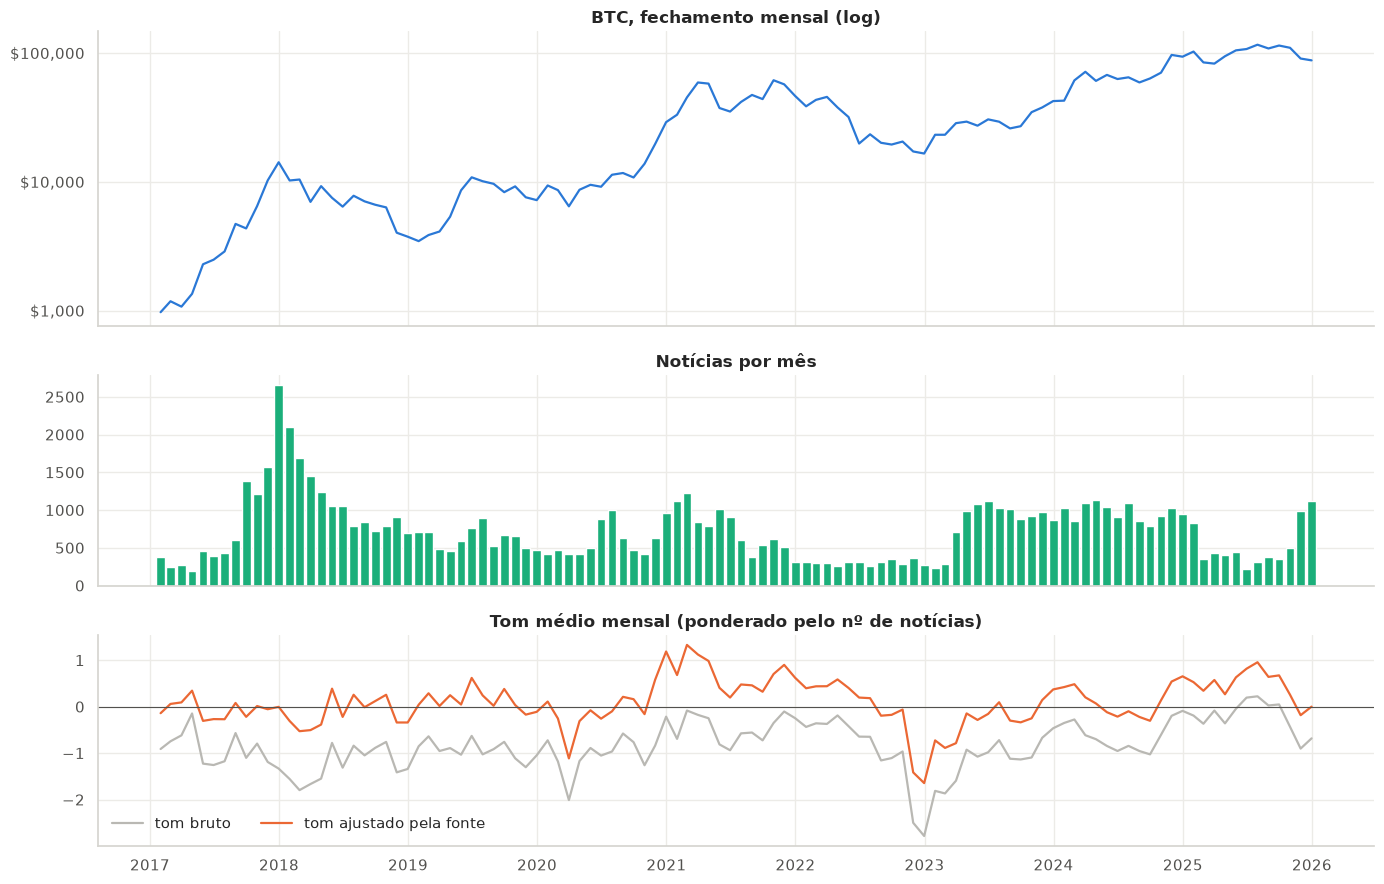

Spearman tom ajustado mensal × retorno mensal do BTC: ρ = 0.161 (p = 0.0977, n = 108 meses)


,notícias,tom ajustado médio,retorno BTC na véspera (%),retorno BTC no dia (%),retorno BTC no dia seguinte (%)
Date,,,,,
2017-12-11,234.0000,0.5100,1.8100,9.1500,2.7900
2018-01-17,190.0000,-0.4200,-18.4600,-2.6600,2.5300
2018-02-06,189.0000,-1.0400,-17.4000,10.8700,-1.7300
2017-11-29,187.0000,0.0100,2.4200,-1.7100,3.4300
2017-12-12,173.0000,0.2600,9.1500,2.7900,-5.9600
2018-01-11,166.0000,-0.6400,2.5600,-11.0600,4.2000
2017-12-19,163.0000,-0.5600,-0.1400,-7.2500,-6.7000
2017-12-08,149.0000,0.3700,22.5100,-7.7200,-8.7700
2017-12-07,146.0000,-0.3200,18.1700,22.5100,-7.7200


Para comparação, |retorno| diário mediano do BTC no período: 1.52%


In [14]:
cov = df.loc[cobertura & (df.index <= "2025-12-31")]
mes = cov.resample("ME").agg({"BTC_Close": "last", "news_count": "sum", "news_tone_adj_sum": "sum", "news_tone_sum": "sum"})
mes["tom_adj"] = mes["news_tone_adj_sum"] / mes["news_count"]
mes["tom_bruto"] = mes["news_tone_sum"] / mes["news_count"]

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True, gridspec_kw={"height_ratios": [1.4, 1, 1]})
axes[0].plot(mes.index, mes["BTC_Close"], color=C[0])
axes[0].set_yscale("log")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
axes[0].set_title("BTC, fechamento mensal (log)")
axes[1].bar(mes.index, mes["news_count"], width=25, color=C[2])
axes[1].set_title("Notícias por mês")
axes[2].plot(mes.index, mes["tom_bruto"], color="#b9b8b3", label="tom bruto")
axes[2].plot(mes.index, mes["tom_adj"], color=C[1], label="tom ajustado pela fonte")
axes[2].axhline(0, color="#52514e", lw=0.8)
axes[2].set_title("Tom médio mensal (ponderado pelo nº de notícias)")
axes[2].legend(frameon=False, loc="lower left", ncol=2)
axes[2].xaxis.set_major_locator(mdates.YearLocator())
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.show()

rho, p = stats.spearmanr(mes["tom_adj"], np.log(mes["BTC_Close"]).diff(), nan_policy="omit")
print(f"Spearman tom ajustado mensal × retorno mensal do BTC: ρ = {rho:.3f} (p = {p:.3g}, n = {mes['tom_adj'].notna().sum()} meses)")

# Os 10 dias com mais notícias: o que o BTC fez nesses dias e na véspera?
rd = np.log(df["BTC_Close"]).diff() * 100
top = cov["news_count"].nlargest(10).to_frame("notícias")
top["tom ajustado médio"] = (cov["news_tone_adj_sum"] / cov["news_count"]).loc[top.index]
top["retorno BTC na véspera (%)"] = rd.shift(1).loc[top.index]
top["retorno BTC no dia (%)"] = rd.loc[top.index]
top["retorno BTC no dia seguinte (%)"] = rd.shift(-1).loc[top.index]
display(top.round(2))
print(f"Para comparação, |retorno| diário mediano do BTC no período: {rd.loc[cov.index].abs().median():.2f}%")

**Leitura:**
- O **tom ajustado** acompanha os grandes episódios do mercado: os meses mais negativos são **nov–dez/2022** (colapso
  da FTX, ≈ −1,5) e **mar/2020** (crash da COVID), e os mais positivos são **dez/2020–mar/2021** (alta que levou o BTC
  de US$ 20 mil a US$ 60 mil, ≈ +1,2). Em frequência mensal, porém, a correlação entre tom e retorno é fraca
  (ρ ≈ 0,16) e não significativa (p ≈ 0,10).
- O tom bruto fica sempre abaixo do ajustado, e a distância entre eles muda com a composição de fontes (por exemplo,
  em 2021, quando a Reuters dominava). Isso confirma que o ajuste por fonte é necessário.
- Os **10 dias com mais notícias** estão todos entre nov/2017 e fev/2018, e quase todos coincidem com movimentos
  grandes do BTC **no próprio dia ou na véspera** (−18% em 17/01/2018, +22% em 07/12/2017, contra uma mediana de 1,5%).
  O retorno do dia seguinte não tem um sinal consistente. É uma primeira pista de que a mídia **reage** aos movimentos.

#### Ciclo semanal das notícias

A mídia tradicional publica menos no fim de semana, e o BTC também oscila menos (H3). Duas séries com o mesmo ciclo
semanal se correlacionam sem que uma cause a outra, então vale medir esse ciclo antes de cruzar as duas trilhas.

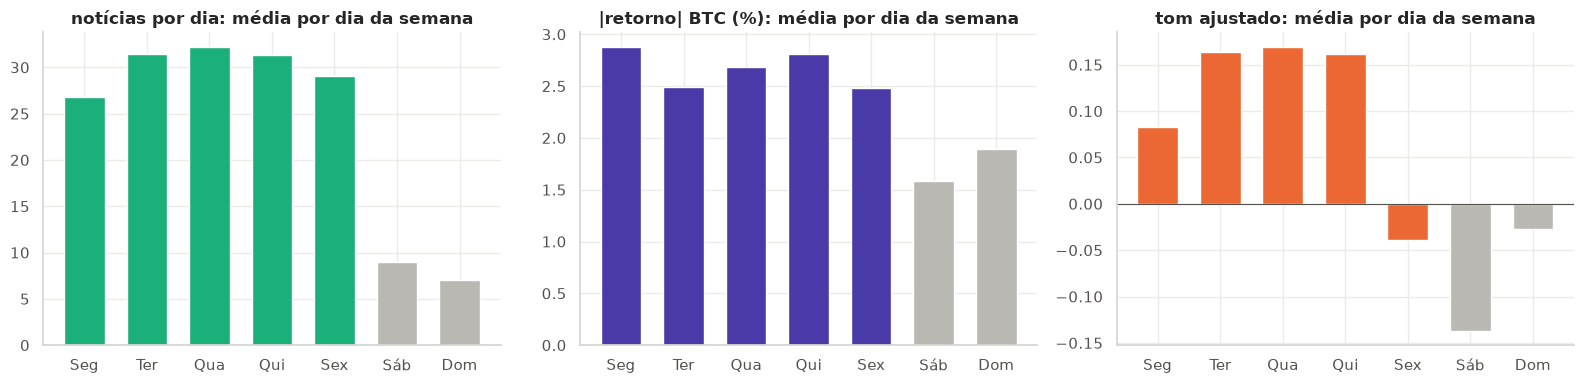

Notícias no fim de semana vs. dias úteis: -73%
Kruskal-Wallis: nº de notícias por dia da semana
   H0: mesma distribuição em todos os dias
   p-valor = 6.335e-285 -> REJEITA H0 (α = 0.05)


In [15]:
semana = pd.DataFrame({
    "notícias por dia": cov["news_count"],
    "|retorno| BTC (%)": rd.loc[cov.index].abs(),
    "tom ajustado": cov["news_tone_adj_sum"] / cov["news_count"],
}).groupby(cov.index.dayofweek).mean().set_axis(dias)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, cor in zip(axes, semana.columns, [C[2], C[6], C[1]]):
    ax.bar(dias, semana[col], color=[cor] * 5 + ["#b9b8b3"] * 2, width=0.65)
    ax.set_title(f"{col}: média por dia da semana")
axes[2].axhline(0, color="#52514e", lw=0.8)
plt.tight_layout()
plt.show()

fim = cov.index.dayofweek >= 5
print(f"Notícias no fim de semana vs. dias úteis: {cov.loc[fim, 'news_count'].mean() / cov.loc[~fim, 'news_count'].mean() - 1:+.0%}")
print("Kruskal-Wallis: nº de notícias por dia da semana")
veredito(stats.kruskal(*[g for _, g in cov["news_count"].groupby(cov.index.dayofweek)]).pvalue, "mesma distribuição em todos os dias")

**Leitura:** o ciclo semanal das notícias é muito mais forte que o do BTC. No fim de semana saem **cerca de 3/4 menos
notícias** (≈ 8 por dia, contra ≈ 30 nos dias úteis), e o tom também fica mais negativo de sexta a domingo. Como o
|retorno| do BTC também cai no fim de semana (H3), qualquer correlação entre atenção e volatilidade terá um componente
de **calendário**. Por isso o indicador de fim de semana entra como controle na H10, e os picos em k = ±7 da H7 são
lidos como efeito de calendário.

#### Temas: como a pauta mudou ao longo do tempo

Os 11 clusters de conceitos (temas e organizações do GDELT agrupados por coocorrência, `news_processing.ipynb`). Uma
notícia pode pertencer a vários clusters, então as participações não somam 100%.

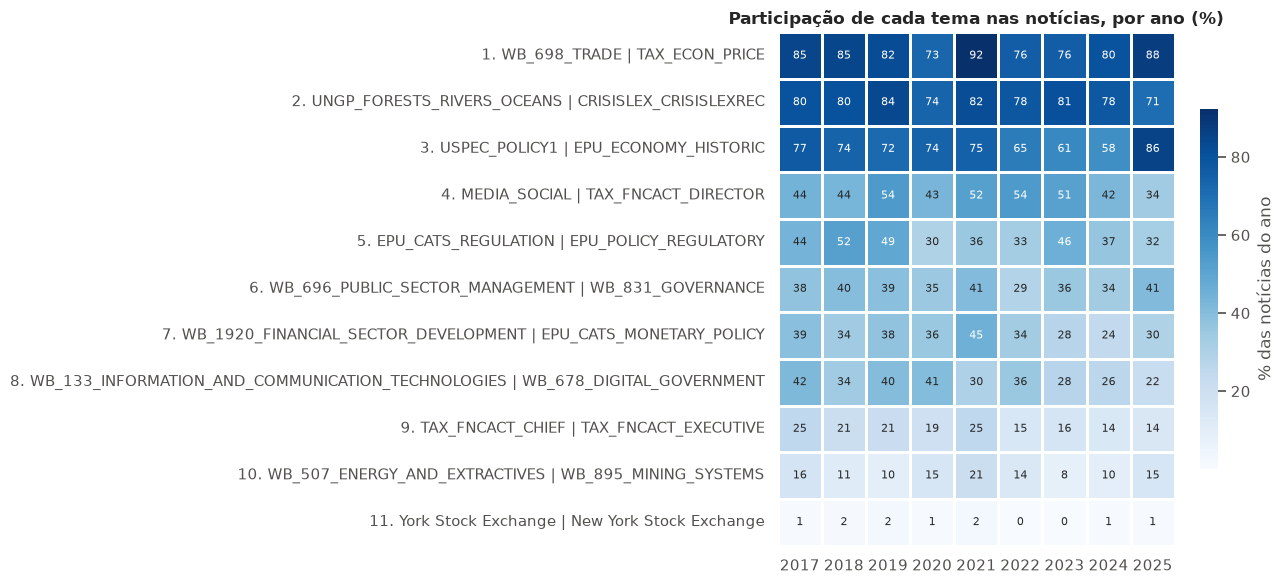

,nº de conceitos,% das notícias (2017-25),tom ajustado médio
1. WB_698_TRADE | TAX_ECON_PRICE,22,81.9100,0.1100
2. UNGP_FORESTS_RIVERS_OCEANS | CRISISLEX_CRISISLEXREC,20,78.6300,-0.0600
3. USPEC_POLICY1 | EPU_ECONOMY_HISTORIC,10,71.3800,0.1100
4. MEDIA_SOCIAL | TAX_FNCACT_DIRECTOR,40,46.5500,0.2000
5. EPU_CATS_REGULATION | EPU_POLICY_REGULATORY,10,39.7400,-0.2200
6. WB_696_PUBLIC_SECTOR_MANAGEMENT | WB_831_GOVERNANCE,6,36.8900,-0.5300
7. WB_1920_FINANCIAL_SECTOR_DEVELOPMENT | EPU_CATS_MONETARY_POLICY,7,34.0800,-0.1600
8. WB_133_INFORMATION_AND_COMMUNICATION_TECHNOLOGIES | WB_678_DIGITAL_GOVERNMENT,5,33.1000,0.3200
9. TAX_FNCACT_CHIEF | TAX_FNCACT_EXECUTIVE,4,19.1400,0.2800
10. WB_507_ENERGY_AND_EXTRACTIVES | WB_895_MINING_SYSTEMS,4,13.4600,0.4600


In [16]:
N_CLUSTERS = int(pd.read_csv(DATA / "news_clusters.csv")["cluster"].max())
clus = pd.read_csv(DATA / "news_clusters.csv")
nomes = clus.groupby("cluster")["nome_cluster"].first()
rotulo = {c: f"{c}. " + " | ".join(nomes[c].split(" | ")[:2]) for c in nomes.index}   # 2 conceitos mais frequentes

cnt_ano = cov.groupby(cov.index.year)[[f"clu{c}_count" for c in nomes.index] + ["news_count"]].sum()
share = cnt_ano[[f"clu{c}_count" for c in nomes.index]].div(cnt_ano["news_count"], axis=0) * 100
share.columns = [rotulo[c] for c in nomes.index]
share = share.loc[2017:2025]

fig, ax = plt.subplots(figsize=(13, 6))
sns.heatmap(share.T, cmap="Blues", annot=True, fmt=".0f", annot_kws={"size": 8}, linewidths=1, linecolor="white",
            cbar_kws={"label": "% das notícias do ano", "shrink": 0.7}, ax=ax)
ax.set_title("Participação de cada tema nas notícias, por ano (%)")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

tom_tema = pd.Series({rotulo[c]: cov[f"clu{c}_tone_adj_sum"].sum() / cov[f"clu{c}_count"].sum() for c in nomes.index})
display(pd.DataFrame({"nº de conceitos": clus.groupby("cluster").size().set_axis(tom_tema.index),
                      "% das notícias (2017-25)": share.mean().values, "tom ajustado médio": tom_tema}).round(2))

**Leitura:**
- Os clusters 1 a 3 são temas **genéricos** do GDELT (comércio/preço, crise, política econômica) e aparecem em mais
  de 70% das notícias: servem pouco para separar assuntos.
- Os clusters **específicos** são mais informativos: **redes sociais** (≈ 47%), **regulação** (≈ 40%), **governança/
  justiça** (≈ 37%), **política monetária/setor financeiro** (≈ 34%) e **mineração/energia** (≈ 13%).
- A pauta se move com os eventos: **regulação** pesa mais em 2018 (52%) e em 2023 (46%, ações da SEC contra
  corretoras e a disputa dos ETFs), e **política monetária/setor financeiro** chega a 45% em 2021.
- Os temas têm tons diferentes: **governança/justiça (−0,53)** e **regulação (−0,22)** são os mais negativos;
  **mineração (+0,46)** e **Bolsa de NY (+0,75)** são os mais positivos. Se algum tema carrega informação própria, ele
  pode estar diluído no tom agregado, e isso é testado na H13.

## 4. Correlações entre as variáveis estruturadas e as notícias

Quais variáveis de mercado se relacionam com as features de notícias (as mesmas usadas na modelagem, em
`modeling/features.py`)? A matriz cruza 9 features de notícias com 12 variáveis estruturadas (BTC, mercados e macro)
e com os 3 alvos do dia seguinte. Retornos de bolsa e câmbio usam apenas dias úteis. São 135 testes; os marcados com
`*` sobrevivem à correção de Holm.

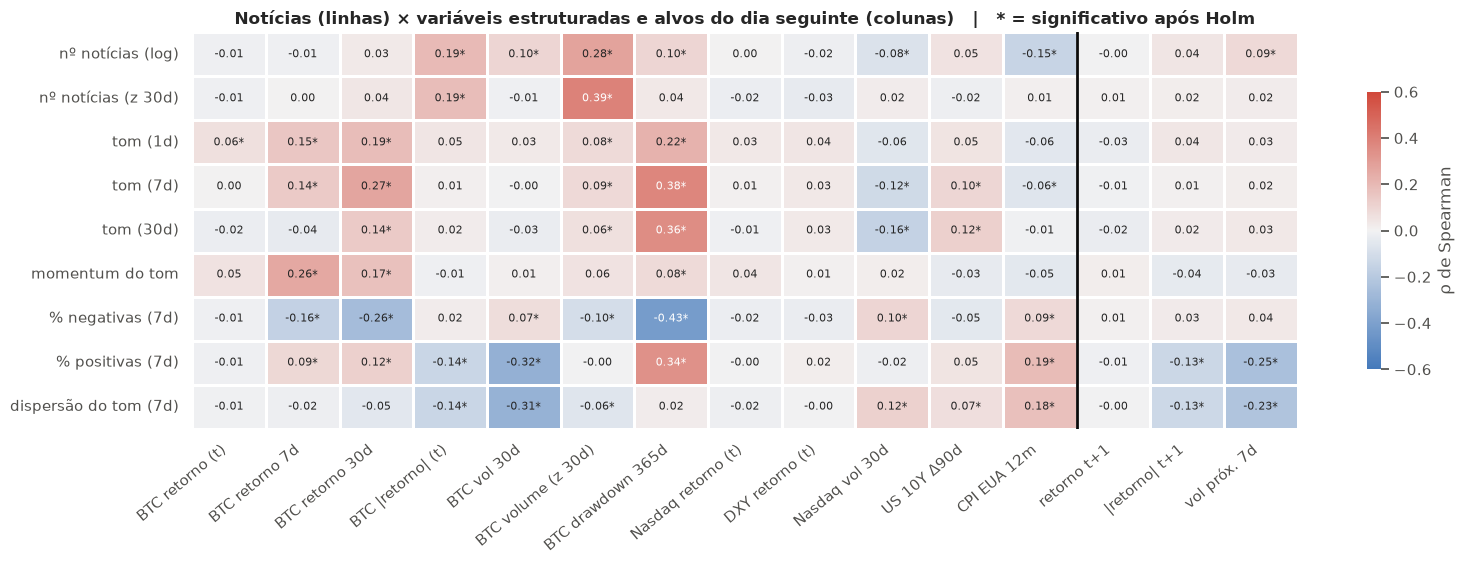

52 de 135 pares significativos após Holm. À direita da linha preta: alvos (t+1).


In [17]:
NEWS_F = {"news_log_count": "nº notícias (log)", "news_count_z30": "nº notícias (z 30d)",
          "news_tone_1d": "tom (1d)", "news_tone_7d": "tom (7d)", "news_tone_30d": "tom (30d)",
          "news_tone_mom": "momentum do tom", "news_neg_share_7d": "% negativas (7d)",
          "news_pos_share_7d": "% positivas (7d)", "news_tone_disp_7d": "dispersão do tom (7d)"}
STRUC_F = {"btc_ret_1d": "BTC retorno (t)", "btc_ret_7d": "BTC retorno 7d", "btc_ret_30d": "BTC retorno 30d",
           "btc_rv_1d": "BTC |retorno| (t)", "btc_rv_30d": "BTC vol 30d", "btc_volume_z30": "BTC volume (z 30d)",
           "btc_drawdown_365": "BTC drawdown 365d", "nasdaq_100_ret_1d": "Nasdaq retorno (t)",
           "us_dxy_ret_1d": "DXY retorno (t)", "nasdaq_rv_30d": "Nasdaq vol 30d",
           "us_10y_chg90": "US 10Y Δ90d", "us_cpi_yoy": "CPI EUA 12m"}
TARGETS = {"target_ret_1d": "retorno t+1", "target_absret_1d": "|retorno| t+1", "target_logvol_7d": "vol próx. 7d"}
DIARIO_UTIL = {"nasdaq_100_ret_1d", "us_dxy_ret_1d"}   # retornos de bolsa: só dias úteis (fim de semana = 0 repetido)
dia_util = data.index.dayofweek < 5

def spearman(d, x, y):
    sub = d.loc[dia_util, [x, y]] if (x in DIARIO_UTIL or y in DIARIO_UTIL) else d[[x, y]]
    sub = sub.dropna()
    return stats.spearmanr(sub[x], sub[y])

cols = {**STRUC_F, **TARGETS}
rho = pd.DataFrame(index=NEWS_F.values(), columns=cols.values(), dtype=float)
pv = rho.copy()
for xn, xl in NEWS_F.items():
    for yn, yl in cols.items():
        rho.loc[xl, yl], pv.loc[xl, yl] = spearman(data, xn, yn)
p_holm = pd.DataFrame(multipletests(pv.values.ravel(), method="holm")[1].reshape(pv.shape), index=pv.index, columns=pv.columns)
anot = rho.map(lambda v: f"{v:.2f}") + p_holm.map(lambda p: "*" if p < ALPHA else "")

fig, ax = plt.subplots(figsize=(16, 5.8))
sns.heatmap(rho, cmap=CMAP_DIV, vmin=-0.6, vmax=0.6, center=0, annot=anot, fmt="", annot_kws={"size": 8},
            linewidths=1, linecolor="white", cbar_kws={"shrink": 0.7, "label": "ρ de Spearman"}, ax=ax)
ax.axvline(len(STRUC_F), color="#0b0b0b", lw=2)
ax.set_title("Notícias (linhas) × variáveis estruturadas e alvos do dia seguinte (colunas)   |   * = significativo após Holm")
ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right")
plt.tight_layout()
plt.show()
print(f"{(p_holm < ALPHA).values.sum()} de {p_holm.size} pares significativos após Holm. À direita da linha preta: alvos (t+1).")

**Leitura:** 52 dos 135 pares são significativos, mas eles se concentram em quatro padrões:

1. **Atenção × intensidade, no mesmo dia:** o número de notícias acompanha o |retorno| do BTC (ρ ≈ 0,19) e
   principalmente o **volume negociado** (ρ ≈ 0,28; o pico de notícias contra o pico de volume chega a ≈ 0,39).
   Dias movimentados geram notícias.
2. **Tom × estado do mercado:** o tom de 7 e de 30 dias acompanha o **drawdown** (ρ ≈ 0,36–0,38) e o retorno dos últimos
   30 dias (≈ 0,27), e a % de notícias negativas sobe quando o BTC está longe do topo (ρ ≈ −0,43). O sentimento descreve
   **onde o mercado está**, e não para onde vai (H12).
3. **Notícias × mercado tradicional:** as correlações com o retorno da Nasdaq e do DXY no mesmo dia são praticamente
   zero. As notícias sobre bitcoin não capturam o canal de **risco global** que move o BTC desde 2020 (H4).
4. **Alvos (à direita da linha):** com o **retorno de t + 1**, nenhuma feature de notícia é significativa. Com
   **|retorno| t + 1** e **volatilidade dos próximos 7 dias**, aparecem a **% de notícias positivas** e a **dispersão do
   tom** (ρ entre −0,13 e −0,25): semanas com cobertura mais positiva e mais heterogênea antecedem períodos mais calmos.

As correlações com o **CPI em 12 meses** (por exemplo, % positivas, ρ ≈ 0,19) são um efeito de período: as duas séries
têm tendências lentas no tempo (inflação alta em 2021–2023, mudança de fontes), sem relação econômica direta. É a
armadilha de 2.2 de novo.

#### H6. A relação das notícias com o BTC é contemporânea ou preditiva?

O heatmap mistura o que acontece **no mesmo dia** com o que acontece **depois**. Para cada feature de notícia,
comparamos a correlação com o BTC do dia *t* (o que já aconteceu) e com o do dia *t + 1* (o que queremos prever):

- **H0:** ρ(notícia em *t*, BTC em *t + 1*) = 0, com correção de Holm para as 18 comparações.

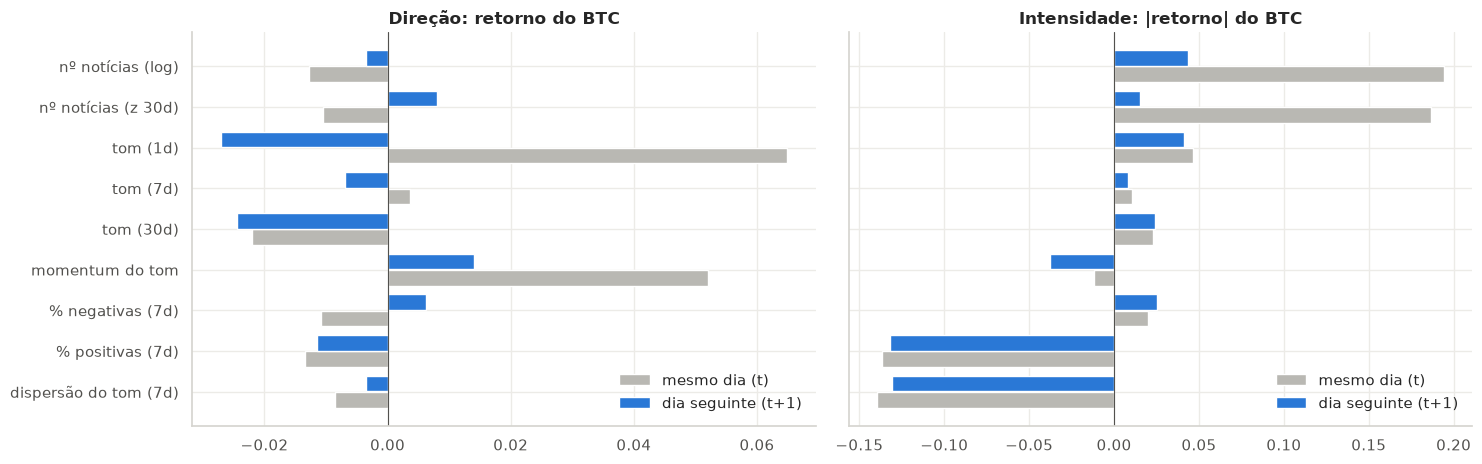

,ρ retorno (t),ρ retorno (t+1),p retorno (t+1),ρ |retorno| (t),ρ |retorno| (t+1),p |retorno| (t+1),Holm retorno (t+1),Holm |retorno| (t+1)
feature,,,,,,,,
nº notícias (log),-0.0127,-0.0035,0.8437,0.1942,0.0436,0.0129,1.0000,0.2066
nº notícias (z 30d),-0.0106,0.0080,0.6490,0.1867,0.0153,0.3843,1.0000,1.0000
tom (1d),0.0649,-0.0271,0.1217,0.0467,0.0409,0.0195,1.0000,0.2932
tom (7d),0.0037,-0.0069,0.6955,0.0104,0.0080,0.6476,1.0000,1.0000
tom (30d),-0.0220,-0.0244,0.1636,0.0227,0.0241,0.1695,1.0000,1.0000
momentum do tom,0.0520,0.0141,0.4227,-0.0118,-0.0376,0.0323,1.0000,0.4521
% negativas (7d),-0.0108,0.0063,0.7199,0.0199,0.0254,0.1488,1.0000,1.0000
% positivas (7d),-0.0135,-0.0114,0.5158,-0.1364,-0.1317,0.0000,1.0000,0.0000
dispersão do tom (7d),-0.0086,-0.0036,0.8391,-0.1396,-0.1306,0.0000,1.0000,0.0000


In [18]:
linhas = []
for xn, xl in NEWS_F.items():
    linhas.append({"feature": xl,
                   "ρ retorno (t)": spearman(data, xn, "btc_ret_1d")[0], "ρ retorno (t+1)": spearman(data, xn, "target_ret_1d")[0],
                   "p retorno (t+1)": spearman(data, xn, "target_ret_1d")[1],
                   "ρ |retorno| (t)": spearman(data, xn, "btc_rv_1d")[0], "ρ |retorno| (t+1)": spearman(data, xn, "target_absret_1d")[0],
                   "p |retorno| (t+1)": spearman(data, xn, "target_absret_1d")[1]})
h6 = pd.DataFrame(linhas).set_index("feature")
holm = multipletests(np.r_[h6["p retorno (t+1)"], h6["p |retorno| (t+1)"]], method="holm")[1]
h6["Holm retorno (t+1)"], h6["Holm |retorno| (t+1)"] = holm[:len(h6)], holm[len(h6):]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
y = np.arange(len(h6))
for ax, (a, b), titulo in [(axes[0], ("ρ retorno (t)", "ρ retorno (t+1)"), "Direção: retorno do BTC"),
                           (axes[1], ("ρ |retorno| (t)", "ρ |retorno| (t+1)"), "Intensidade: |retorno| do BTC")]:
    ax.barh(y + 0.2, h6[a], height=0.38, color="#b9b8b3", label="mesmo dia (t)")
    ax.barh(y - 0.2, h6[b], height=0.38, color=C[0], label="dia seguinte (t+1)")
    ax.axvline(0, color="#52514e", lw=0.8)
    ax.set_title(titulo)
    ax.legend(frameon=False, loc="lower right")
axes[0].set_yticks(y, h6.index)
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()
display(h6.round(4))

**Conclusão H6:** a relação das notícias com o BTC é **contemporânea**:
- **Direção:** a maior correlação é a do tom do dia com o retorno **do mesmo dia** (ρ ≈ 0,06). Com o retorno de t + 1,
  nenhuma das 9 features passa na correção de Holm (|ρ| ≤ 0,03).
- **Intensidade:** o número de notícias tem ρ ≈ 0,19 com o |retorno| do mesmo dia, mas só ≈ 0,04 com o de t + 1 (não
  significativo após Holm). As únicas relações que se mantêm no dia seguinte são a **% de notícias positivas** e a
  **dispersão do tom**, porque elas são médias de 7 dias e acompanham o **regime** de volatilidade, que é persistente
  (H2). A H10 testa se elas trazem algo além da volatilidade passada.

As seções 5 e 6 aprofundam a parte de direção com defasagens, causalidade de Granger e estudo de eventos.

## 5. O sentimento antecipa o retorno do BTC?

#### H7. Correlação defasada entre tom e retorno

Calculamos a correlação de Spearman entre o tom do dia *t* e o retorno do BTC no dia *t + k*, para k de −10 a +10.

- **k > 0** (tom antes do retorno): o sentimento **antecipa** o preço, que é o que seria útil para prever a direção.
- **k < 0** (retorno antes do tom): o sentimento **reage** ao preço.

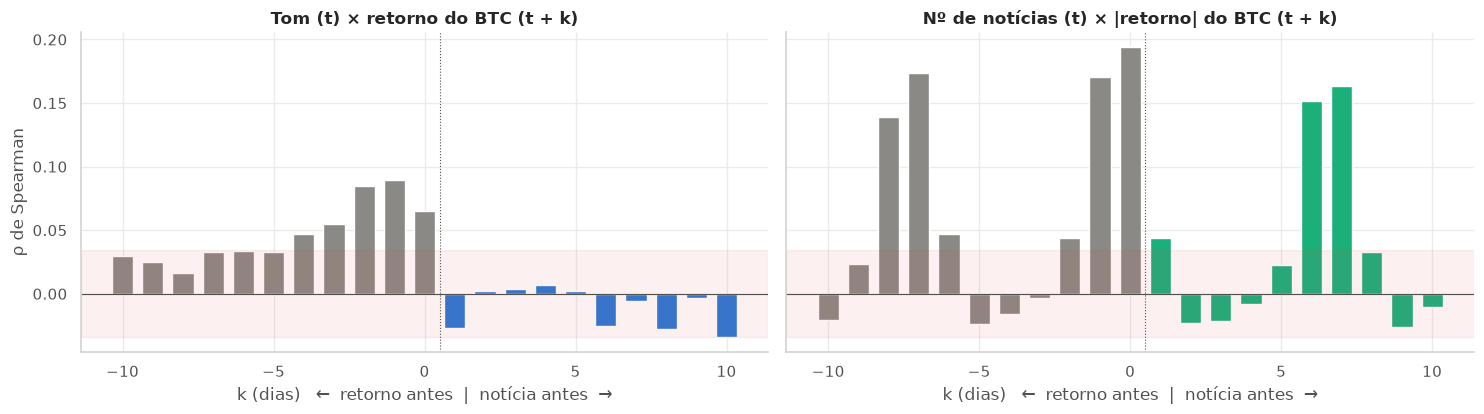

,-10,-9,-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7,8,9,10
tom,0.0290,0.0250,0.0160,0.0330,0.0330,0.0330,0.0470,0.0550,0.0840,0.0890,0.0650,-0.0270,0.0030,0.0040,0.0070,0.0020,-0.0250,-0.0050,-0.0280,-0.0030,-0.0340
atencao_vs_vol,-0.0200,0.0230,0.1390,0.1740,0.0470,-0.0240,-0.0160,-0.0040,0.0440,0.1700,0.1940,0.0440,-0.0230,-0.0220,-0.0080,0.0230,0.1520,0.1640,0.0330,-0.0260,-0.0110


Faixa de ±0.034 = não significativo a 5% (aprox.)


In [19]:
lags = range(-10, 11)
cc = pd.DataFrame({
    "tom": [stats.spearmanr(data["news_tone_1d"], r.shift(-k), nan_policy="omit")[0] for k in lags],
    "atencao_vs_vol": [stats.spearmanr(data["news_log_count"], r.abs().shift(-k), nan_policy="omit")[0] for k in lags],
}, index=list(lags))
lim = 1.96 / np.sqrt(len(data))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3), sharey=True)
for ax, col, titulo, cor in [(axes[0], "tom", "Tom (t) × retorno do BTC (t + k)", C[0]),
                             (axes[1], "atencao_vs_vol", "Nº de notícias (t) × |retorno| do BTC (t + k)", C[2])]:
    ax.bar(cc.index, cc[col], color=[cor if k > 0 else GRAY for k in cc.index], width=0.7)
    ax.axhspan(-lim, lim, color=C[7], alpha=0.08)
    ax.axhline(0, color="#52514e", lw=0.8)
    ax.axvline(0.5, color="#52514e", lw=0.8, ls=":")
    ax.set_title(titulo)
    ax.set_xlabel("k (dias)   ←  retorno antes  |  notícia antes  →")
axes[0].set_ylabel("ρ de Spearman")
plt.tight_layout()
plt.show()
display(cc.round(3).T)
print(f"Faixa de ±{lim:.3f} = não significativo a 5% (aprox.)")

**Leitura:** as correlações significativas estão nos k **≤ 0**, em cinza: o tom de hoje se relaciona com o retorno de
**hoje e dos dias anteriores**, e não com o de amanhã (em k = +1 ela é praticamente zero). O mesmo vale para a atenção:
o número de notícias acompanha o |retorno| do próprio dia e do dia anterior. É o padrão de uma mídia que **noticia o que
o preço já fez**.

Os picos em k = ±7 no gráfico da direita são **calendário**, e não efeito causal: nos fins de semana há menos notícias
(cerca de 3/4 a menos, ver o ciclo semanal na seção 3) e o BTC também oscila menos, então as duas séries têm o mesmo ciclo semanal.

#### H8. Causalidade de Granger entre tom e retorno

- **H0:** o passado de X não melhora a previsão de Y além do próprio passado de Y. Defasagens de 1 a 7 dias.

In [20]:
import contextlib, io
from statsmodels.tsa.stattools import grangercausalitytests

def granger_p(dados, y, x, maxlag):
    # o argumento verbose saiu no statsmodels 0.15: silenciamos a impressão por fora
    with contextlib.redirect_stdout(io.StringIO()):
        res = grangercausalitytests(dados[[y, x]].dropna(), maxlag=maxlag)
    return {f"lag {l}": res[l][0]["ssr_ftest"][1] for l in res}

g = data[["btc_ret_1d", "news_tone_1d", "news_log_count"]].assign(btc_abs=r.abs()).dropna()
gr = pd.DataFrame({
    "tom → retorno BTC": granger_p(g, "btc_ret_1d", "news_tone_1d", 7),
    "retorno BTC → tom": granger_p(g, "news_tone_1d", "btc_ret_1d", 7),
    "nº notícias → |retorno|": granger_p(g, "btc_abs", "news_log_count", 7),
    "|retorno| → nº notícias": granger_p(g, "news_log_count", "btc_abs", 7),
}).T
display(gr.style.format("{:.4f}").map(lambda v: "font-weight: bold" if v < ALPHA else ""))

,lag 1,lag 2,lag 3,lag 4,lag 5,lag 6,lag 7
tom → retorno BTC,0.2817,0.4145,0.5678,0.6465,0.7384,0.4430,0.5788
retorno BTC → tom,0.0004,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
nº notícias → |retorno|,0.1033,0.4190,0.0257,0.1360,0.0319,0.0000,0.0000
|retorno| → nº notícias,0.0000,0.0000,0.0003,0.0010,0.0000,0.0001,0.0084


**Leitura:** a causalidade de Granger vai **do preço para a notícia**: o retorno do BTC antecede o tom das notícias com
p < 0,001 em todas as defasagens, e o contrário não é significativo em nenhuma.

Na atenção, o |retorno| antecede fortemente o número de notícias (p < 0,01 em todas as defasagens). O sentido contrário
só fica significativo nas defasagens 6 e 7, de novo o **ciclo semanal**, e não informação nova. Ou seja, também aqui o
preço se move primeiro.

## 6. Estudo de eventos (event study)

O estudo de eventos é a ferramenta clássica de finanças para medir o efeito de um evento no preço, e dá nome ao projeto
(*Market Analysis Driven by Event Studies*). Procedimento:

1. **Evento = choque de sentimento:** dia em que o tom diário fica a mais de 2 desvios-padrão da sua média dos 90 dias
   **anteriores** (z-score só com o passado), em dias com pelo menos 5 notícias. Choques negativos e positivos são
   analisados separadamente.
2. **Declustering:** eventos a menos de 10 dias de outro do mesmo tipo são descartados, para as janelas não se
   sobreporem.
3. **Retorno anormal (AR)** = retorno do BTC − retorno médio na janela de estimação [−120, −11] dias (modelo de média
   constante, o padrão em cripto, que negocia 7 dias por semana).
4. **CAR** (retorno anormal acumulado) em janelas antes e depois do evento, com teste t, Wilcoxon e um **teste placebo**
   (1.000 sorteios de datas falsas), que é robusto a caudas pesadas.

Se o sentimento **antecipa** o preço, o CAR deve aparecer **depois** do evento ([+1, +5]). Se ele **reage**, o CAR
aparece **antes** ([−5, −1]).

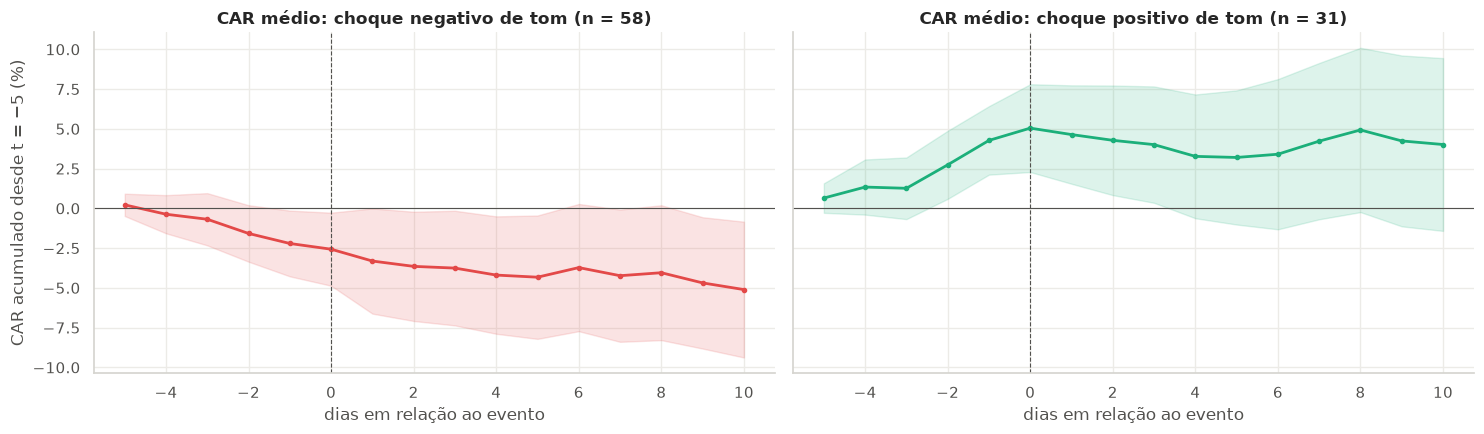


CHOQUE NEGATIVO DE TOM  (n = 58)


,CAR_medio_%,CAR_mediano_%,%_positivos,t,p_t,p_wilcoxon
janela,,,,,,
"[-5, -1]",-2.2080,-0.8210,43.1030,-2.0930,0.0410,0.0850
"[+0, +0]",-0.3600,-0.0350,50.0000,-0.7180,0.4750,0.5590
"[+1, +1]",-0.7440,0.2160,51.7240,-0.7620,0.4490,0.7250
"[+1, +5]",-1.7600,-1.4590,41.3790,-1.1980,0.2360,0.2200
"[+1, +10]",-2.5390,-2.3910,37.9310,-1.5010,0.1390,0.1120



CHOQUE POSITIVO DE TOM  (n = 31)


,CAR_medio_%,CAR_mediano_%,%_positivos,t,p_t,p_wilcoxon
janela,,,,,,
"[-5, -1]",4.2730,3.1940,74.1940,3.8910,0.0010,0.0010
"[+0, +0]",0.7730,0.4670,64.5160,1.1950,0.2420,0.1110
"[+1, +1]",-0.4040,0.2810,54.8390,-0.6080,0.5480,0.7500
"[+1, +5]",-1.8440,0.4750,51.6130,-1.0580,0.2990,0.4210
"[+1, +10]",-1.0300,-0.9630,48.3870,-0.4090,0.6850,0.7790


In [21]:
from modeling.event_study import detect_events, abnormal_returns, car_table, placebo_test

valid = df["news_count"].reindex(data.index) >= 5
ev = {
    "choque negativo de tom": detect_events(data["news_tone_z90"], 2.0, "neg", 10, valid),
    "choque positivo de tom": detect_events(data["news_tone_z90"], 2.0, "pos", 10, valid),
}
ars = {nome: abnormal_returns(r, e) for nome, e in ev.items()}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, (nome, ar), cor in zip(axes, ars.items(), [C[7], C[2]]):
    car = ar.cumsum(axis=1) * 100
    m, se = car.mean(), car.std() / np.sqrt(len(car))
    ax.plot(m.index, m, color=cor, lw=2, marker="o", ms=3)
    ax.fill_between(m.index, m - 1.96 * se, m + 1.96 * se, color=cor, alpha=0.15)
    ax.axvline(0, color="#52514e", lw=0.8, ls="--")
    ax.axhline(0, color="#52514e", lw=0.8)
    ax.set_title(f"CAR médio: {nome} (n = {len(ar)})")
    ax.set_xlabel("dias em relação ao evento")
axes[0].set_ylabel("CAR acumulado desde t = −5 (%)")
plt.tight_layout()
plt.show()

for nome, ar in ars.items():
    print(f"\n{nome.upper()}  (n = {len(ar)})")
    display(car_table(ar).round(3))

In [22]:
candidatos = data.index[valid & data["news_tone_z90"].notna()]
candidatos = candidatos[(candidatos > candidatos[0] + pd.Timedelta(days=130)) & (candidatos < candidatos[-1] - pd.Timedelta(days=15))]

linhas = []
for nome, e in ev.items():
    for janela in [(-5, -1), (1, 5)]:
        real, sims, p = placebo_test(r, e, candidatos, window=janela, n_iter=1000)
        linhas.append({"evento": nome, "janela": f"[{janela[0]:+d}, {janela[1]:+d}]", "CAR real (%)": real * 100,
                       "CAR placebo médio (%)": sims.mean() * 100, "p-valor placebo": p})
placebo = pd.DataFrame(linhas).set_index(["evento", "janela"])
display(placebo.round(4))

CAR real (%)  CAR placebo médio (%)  p-valor placebo
evento                 janela                                                        
choque negativo de tom [-5, -1]       -2.2078                -0.2062           0.0559
                       [+1, +5]       -1.7598                -0.2824           0.1528
choque positivo de tom [-5, -1]        4.2733                -0.1980           0.0040
                       [+1, +5]       -1.8442                -0.2441           0.2757

**Leitura:**
- Antes dos **choques positivos** de tom, o BTC acumula um retorno anormal de cerca de **+4%** nos 5 dias anteriores
  (≈ 74% dos eventos com CAR positivo; significativo no teste t, no Wilcoxon e no placebo). Depois do evento, o CAR é
  estatisticamente zero.
- Antes dos **choques negativos**, o CAR é de cerca de **−2%** (significativo no teste t, marginal nos outros), e depois
  ele também não é significativo.

Os dois choques são **precedidos** por movimento de preço na mesma direção e **não são seguidos** por movimento
significativo. Depois dos choques negativos, o CAR médio continua caindo (≈ −2,5% em 10 dias), mas sem significância
(p ≈ 0,14, e o IC do gráfico é largo). Vale acompanhar com mais eventos, mas hoje não é evidência. É a evidência mais direta de que o sentimento do GDELT **reage** ao preço.

#### H9. A atenção da mídia antecipa a volatilidade?

Mesmo que o tom não dê a direção, um pico de **volume de notícias** poderia anunciar dias turbulentos. Evento: número
de notícias a mais de 2 desvios-padrão da média dos 30 dias anteriores. Medimos o |AR| (tamanho do movimento) em torno do
evento, comparado ao |retorno| médio da janela de estimação.

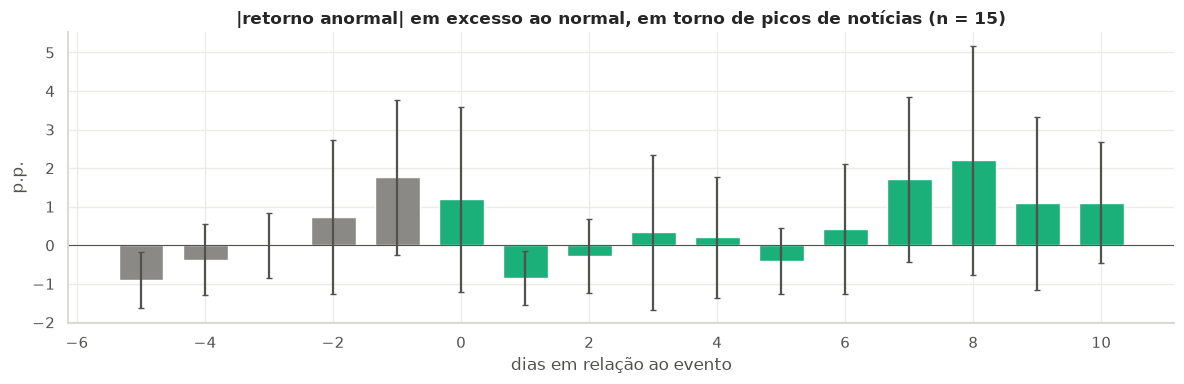

Janela [-5, -1]: excesso médio de |AR| = 0.24 p.p.
   H0: |AR| igual ao normal
   p-valor = 0.5995 -> NÃO rejeita H0 (α = 0.05)
Janela [+0, +0]: excesso médio de |AR| = 1.19 p.p.
   H0: |AR| igual ao normal
   p-valor = 1 -> NÃO rejeita H0 (α = 0.05)
Janela [+1, +5]: excesso médio de |AR| = -0.20 p.p.
   H0: |AR| igual ao normal
   p-valor = 0.3303 -> NÃO rejeita H0 (α = 0.05)


In [23]:
ev_att = detect_events(data["news_count_z30"], 2.0, "pos", 10, valid)
ar_att = abnormal_returns(r, ev_att)
base_abs = pd.Series({e: r.loc[e - pd.Timedelta(days=120): e - pd.Timedelta(days=11)].abs().mean() for e in ar_att.index})
excesso = ar_att.abs().sub(base_abs, axis=0) * 100

fig, ax = plt.subplots(figsize=(12, 4))
m, se = excesso.mean(), excesso.std() / np.sqrt(len(excesso))
ax.bar(m.index, m, color=[C[2] if k >= 0 else GRAY for k in m.index], width=0.7)
ax.errorbar(m.index, m, yerr=1.96 * se, fmt="none", ecolor="#52514e", capsize=2)
ax.axhline(0, color="#52514e", lw=0.8)
ax.set_title(f"|retorno anormal| em excesso ao normal, em torno de picos de notícias (n = {len(ar_att)})")
ax.set_xlabel("dias em relação ao evento")
ax.set_ylabel("p.p.")
plt.tight_layout()
plt.show()

for jan in [(-5, -1), (0, 0), (1, 5)]:
    x = excesso.loc[:, jan[0]:jan[1]].mean(axis=1)
    print(f"Janela [{jan[0]:+d}, {jan[1]:+d}]: excesso médio de |AR| = {x.mean():.2f} p.p.")
    veredito(stats.wilcoxon(x).pvalue, "|AR| igual ao normal")

**Leitura:** a média do excesso de |AR| no dia do pico (≈ +1,2 p.p.) é puxada por 2 eventos extremos; a mediana é
negativa e nenhum teste é significativo. Picos isolados de notícias são raros depois do declustering (n = 15), então o
poder do teste é baixo. Por isso a atenção também foi testada como feature contínua no modelo de volatilidade
(H10 logo abaixo e notebook de modelagem), que usa todos os dias e não só os picos.

## 7. Notícias × volatilidade

A volatilidade é a parte previsível do BTC (H2). Mesmo que as notícias não deem a direção, elas poderiam ajudar a
prever **quanto** o preço vai se mover.

#### Como a cobertura muda entre períodos calmos e turbulentos

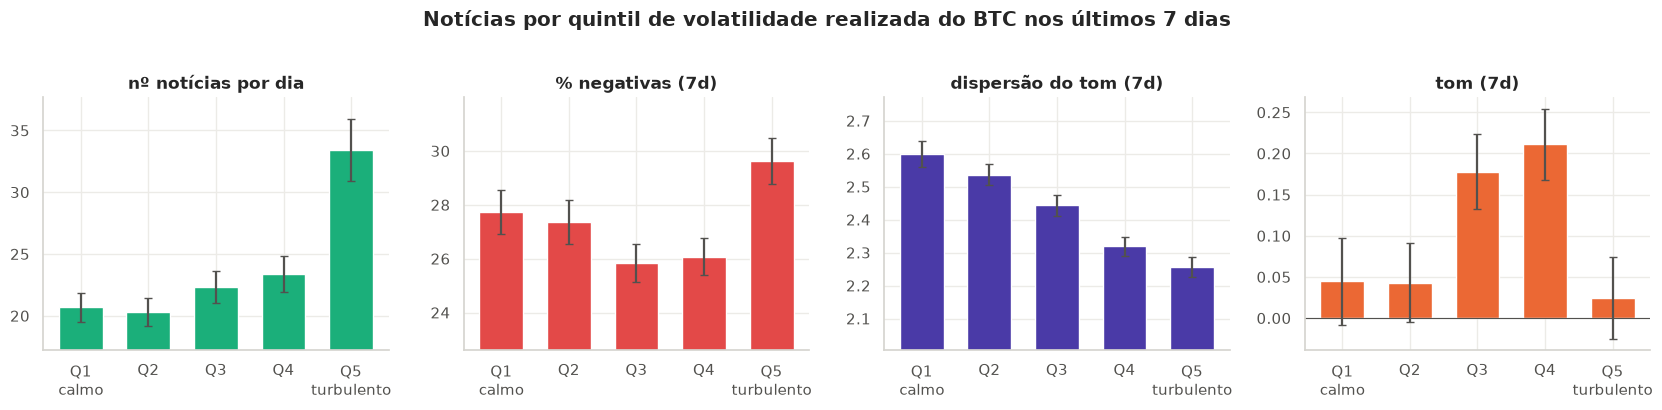

Kruskal-Wallis: nº notícias por dia
   H0: mesma distribuição nos 5 quintis
   p-valor = 7.209e-13 -> REJEITA H0 (α = 0.05)
Kruskal-Wallis: % negativas (7d)
   H0: mesma distribuição nos 5 quintis
   p-valor = 1.261e-09 -> REJEITA H0 (α = 0.05)
Kruskal-Wallis: dispersão do tom (7d)
   H0: mesma distribuição nos 5 quintis
   p-valor = 2.06e-52 -> REJEITA H0 (α = 0.05)
Kruskal-Wallis: tom (7d)
   H0: mesma distribuição nos 5 quintis
   p-valor = 7.436e-09 -> REJEITA H0 (α = 0.05)


In [24]:
quint = pd.qcut(data["btc_rv_7d"], 5, labels=["Q1 (calmo)", "Q2", "Q3", "Q4", "Q5 (turbulento)"])
vq = pd.DataFrame({"nº notícias por dia": df["news_count"].reindex(data.index), "% negativas (7d)": data["news_neg_share_7d"] * 100,
                   "dispersão do tom (7d)": data["news_tone_disp_7d"], "tom (7d)": data["news_tone_7d"], "quintil": quint}).dropna()
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, col, cor in zip(axes, vq.columns[:4], [C[2], C[7], C[6], C[1]]):
    g = vq.groupby("quintil", observed=True)[col]
    ax.bar(range(5), g.mean(), color=cor, width=0.65)
    ax.errorbar(range(5), g.mean(), yerr=1.96 * g.sem(), fmt="none", ecolor="#52514e", capsize=3)
    ax.set_xticks(range(5), ["Q1\ncalmo", "Q2", "Q3", "Q4", "Q5\nturbulento"])
    ax.set_title(col)
    lo = (g.mean() - 2 * g.sem()).min()
    if lo > 0:
        ax.set_ylim(lo * 0.9, None)
axes[3].axhline(0, color="#52514e", lw=0.8)
fig.suptitle("Notícias por quintil de volatilidade realizada do BTC nos últimos 7 dias", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()
for col in vq.columns[:4]:
    print(f"Kruskal-Wallis: {col}")
    veredito(stats.kruskal(*[g for _, g in vq.groupby("quintil", observed=True)[col]]).pvalue, "mesma distribuição nos 5 quintis")

**Leitura:** a cobertura muda bastante com o nível de volatilidade dos últimos 7 dias (todos os Kruskal-Wallis
significativos):
- **número de notícias:** estável até o 4º quintil e salta no 5º (≈ 21 → 33 por dia). A mídia reage aos períodos
  mais turbulentos;
- **% de notícias negativas:** forma de U, maior nos dois extremos (calmo e turbulento);
- **dispersão do tom:** **cai** de forma monotônica com a volatilidade (2,60 → 2,26). Nos períodos turbulentos a
  cobertura fica mais **homogênea**, com todas as notícias falando do mesmo movimento. Nos calmos, a pauta é variada;
- **tom médio:** maior nos quintis intermediários e próximo de zero nos extremos.

Tudo isso é **contemporâneo**. A pergunta preditiva vem a seguir.

#### H10. As notícias antecipam a volatilidade além do que a volatilidade passada já diz?

A volatilidade tem memória longa (H2), e as notícias acompanham a volatilidade do momento (acima). Por isso, uma
correlação alta entre notícias hoje e volatilidade futura pode ser só a volatilidade de hoje "passando" pelas notícias.
O teste justo é a **correlação parcial**: retiramos de cada variável o que é explicado pelos componentes do modelo HAR
(|retorno| de hoje, volatilidade de 7 e de 30 dias) e pelo indicador de fim de semana, e correlacionamos os resíduos
(em postos, ou seja, uma Spearman parcial).

- **H0:** ρ parcial = 0, com correção de Holm.
- **Alvos:** |retorno| em *t + 1* e volatilidade realizada dos próximos 7 dias. O segundo usa janelas sobrepostas, então
  os p-valores dele são otimistas (as observações não são independentes).

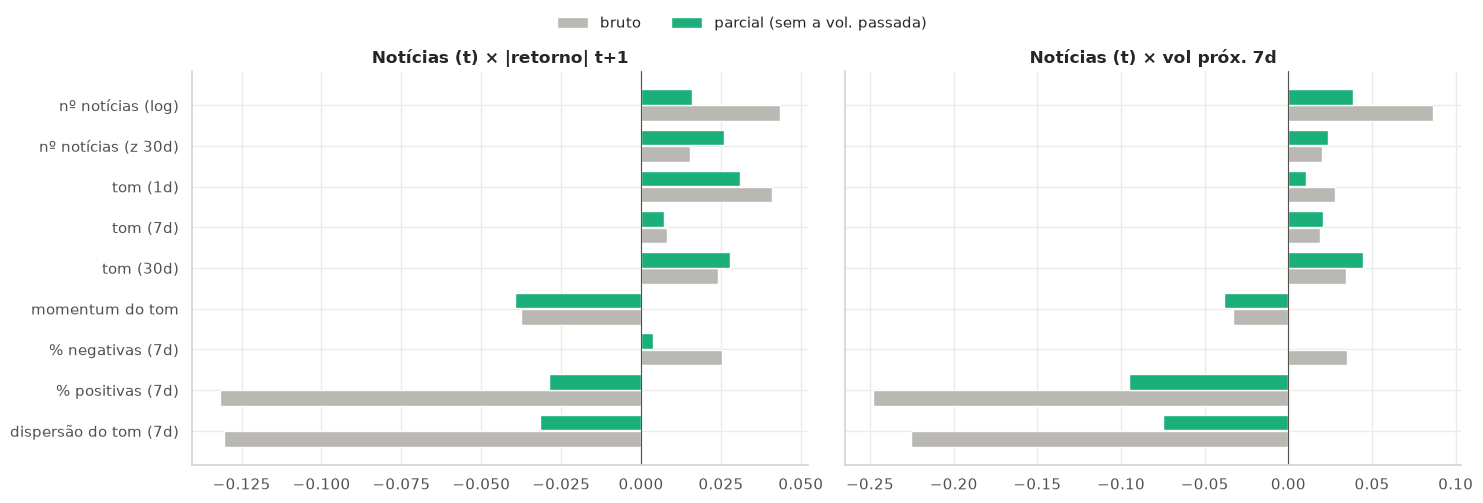

Para comparação: ρ(vol 30d passada, vol próx. 7d) = 0.482


ρ bruto  ρ parcial  p parcial  p Holm  signif. (Holm)
alvo          feature                                                                     
vol próx. 7d  % positivas (7d)       -0.2482    -0.0953     0.0000  0.0000            True
              dispersão do tom (7d)  -0.2254    -0.0749     0.0000  0.0003            True
              tom (30d)               0.0342     0.0448     0.0106  0.1702           False
              nº notícias (log)       0.0865     0.0388     0.0270  0.3777           False
              momentum do tom        -0.0330    -0.0384     0.0292  0.3790           False
              nº notícias (z 30d)     0.0200     0.0234     0.1818  1.0000           False
              tom (7d)                0.0187     0.0204     0.2454  1.0000           False
              tom (1d)                0.0281     0.0107     0.5428  1.0000           False
              % negativas (7d)        0.0352    -0.0001     0.9972  1.0000           False
|retorno| t+1 momentum do tom        -0.0376    -0.0396     0.0243  0.3647           False
              dispersão do tom (7d)  -0.1306    -0.0316     0.0716  0.8591           False
              tom (1d)                0.0409     0.0310     0.0771  0.8591           False
              % positivas (7d)       -0.1317    -0.0288     0.1013  1.0000           False
              tom (30d)               0.0241     0.0278     0.1129  1.0000           False
              nº notícias (z 30d)     0.0153     0.0258     0.1412  1.0000           False
              nº notícias (log)       0.0436     0.0158     0.3676  1.0000           False
              tom (7d)                0.0080     0.0071     0.6881  1.0000           False
              % negativas (7d)        0.0254     0.0036     0.8377  1.0000           False

In [25]:
CTRL = ["btc_rv_1d", "btc_rv_7d", "btc_rv_30d", "is_weekend"]

def spearman_parcial(d, x, y, ctrl):
    sub = d[[x, y] + ctrl].dropna().rank()
    Z = np.column_stack([np.ones(len(sub)), sub[ctrl]])
    res = lambda v: v - Z @ np.linalg.lstsq(Z, v, rcond=None)[0]
    return stats.pearsonr(res(sub[x].values), res(sub[y].values))

linhas = []
for xn, xl in NEWS_F.items():
    for alvo, al in [("target_absret_1d", "|retorno| t+1"), ("target_logvol_7d", "vol próx. 7d")]:
        bruto = spearman(data, xn, alvo)[0]
        rp, pp = spearman_parcial(data, xn, alvo, CTRL)
        linhas.append({"feature": xl, "alvo": al, "ρ bruto": bruto, "ρ parcial": rp, "p parcial": pp})
h10 = pd.DataFrame(linhas)
h10["p Holm"] = multipletests(h10["p parcial"], method="holm")[1]
h10["signif. (Holm)"] = h10["p Holm"] < ALPHA

# Referência: quanto a própria volatilidade passada explica
ref = spearman(data, "btc_rv_30d", "target_logvol_7d")[0]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, al in zip(axes, ["|retorno| t+1", "vol próx. 7d"]):
    t = h10[h10["alvo"] == al].set_index("feature")
    y = np.arange(len(t))
    ax.barh(y + 0.2, t["ρ bruto"], height=0.38, color="#b9b8b3", label="bruto")
    ax.barh(y - 0.2, t["ρ parcial"], height=0.38, color=C[2], label="parcial (sem a vol. passada)")
    ax.axvline(0, color="#52514e", lw=0.8)
    ax.set_title(f"Notícias (t) × {al}")
axes[0].set_yticks(np.arange(len(NEWS_F)), list(NEWS_F.values()))
axes[0].invert_yaxis()
fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, 1.06))
plt.tight_layout()
plt.show()
print(f"Para comparação: ρ(vol 30d passada, vol próx. 7d) = {ref:.3f}")
display(h10.sort_values(["alvo", "p parcial"]).set_index(["alvo", "feature"]).round(4))

**Conclusão H10:** quase toda a relação entre notícias e volatilidade futura **é a própria volatilidade passada**.
- A volatilidade passada sozinha tem ρ ≈ 0,48 com a volatilidade dos próximos 7 dias. As maiores correlações brutas das
  notícias (≈ −0,25) caem para **|ρ| < 0,10** quando ela é controlada.
- Para o **|retorno| de t + 1** (alvo sem sobreposição), **nenhuma** feature de notícia é significativa após Holm.
- Para a **volatilidade dos próximos 7 dias**, sobram dois efeitos pequenos e significativos: a **% de notícias
  positivas** (ρ parcial ≈ −0,10) e a **dispersão do tom** (≈ −0,07). Como esse alvo usa janelas sobrepostas, os
  p-valores são otimistas, e o efeito deve ser confirmado fora da amostra.

**Implicação:** as notícias podem trazer um ganho **marginal** a um modelo de volatilidade (HAR-X), por meio do tom e da
dispersão, e não do volume. Essa ablação é feita no `modeling_baseline.ipynb` (H14).

## 8. Estabilidade e regimes

As seções anteriores usam o período inteiro. Uma correlação média próxima de zero pode esconder períodos de relação
forte (positiva ou negativa), e o BTC mudou de regime em 2020 (H4).

#### Correlação móvel de 1 ano

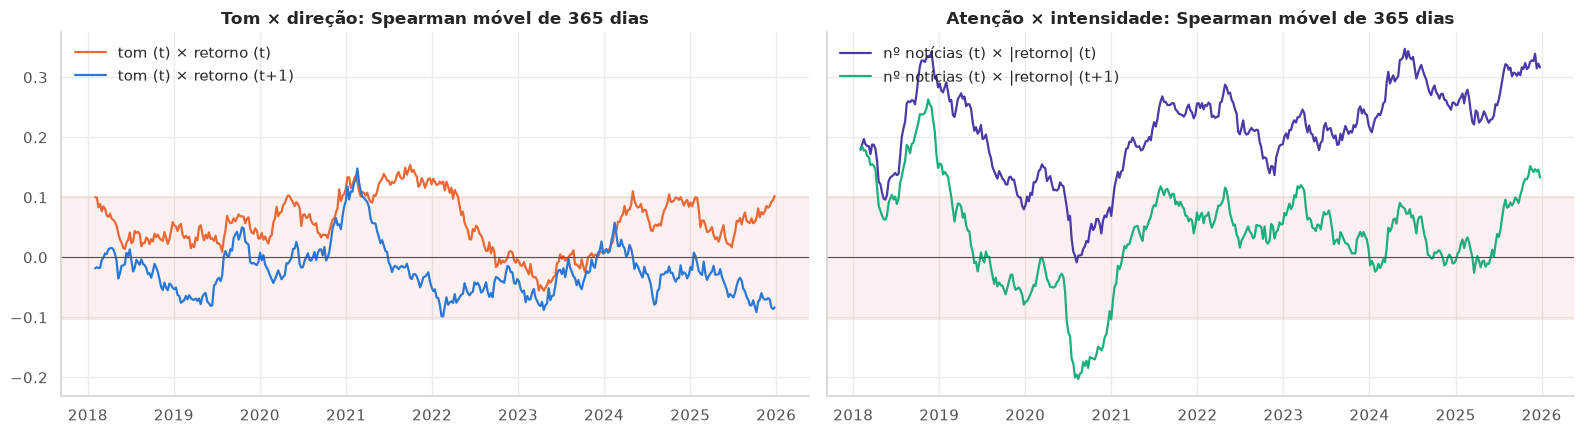

In [26]:
PARES = {"tom (t) × retorno (t)": ("news_tone_1d", "btc_ret_1d"),
         "tom (t) × retorno (t+1)": ("news_tone_1d", "target_ret_1d"),
         "nº notícias (t) × |retorno| (t)": ("news_log_count", "btc_rv_1d"),
         "nº notícias (t) × |retorno| (t+1)": ("news_log_count", "target_absret_1d")}
JAN = 365
datas = data.index[JAN::7]
movel = pd.DataFrame({nome: [stats.spearmanr(*data.loc[t - pd.Timedelta(days=JAN - 1): t, [x, y]].dropna().T.values)[0]
                             for t in datas] for nome, (x, y) in PARES.items()}, index=datas)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
for ax, nomes_p, cores in [(axes[0], list(PARES)[:2], [C[1], C[0]]), (axes[1], list(PARES)[2:], [C[6], C[2]])]:
    for nome, cor in zip(nomes_p, cores):
        ax.plot(movel.index, movel[nome], color=cor, label=nome)
    ax.axhline(0, color="#52514e", lw=0.8)
    ax.axhspan(-1.96 / np.sqrt(JAN), 1.96 / np.sqrt(JAN), color=C[7], alpha=0.08)
    ax.legend(frameon=False, loc="upper left")
axes[0].set_title("Tom × direção: Spearman móvel de 365 dias")
axes[1].set_title("Atenção × intensidade: Spearman móvel de 365 dias")
plt.tight_layout()
plt.show()

**Leitura:** a faixa sombreada é o intervalo de ±1,96/√365 ≈ ±0,10 (não significativo a 5%).
- **Tom × direção:** a correlação com o retorno **do mesmo dia** (laranja) é positiva em quase todo o período e chega a
  ≈ 0,15 em 2021, ano em que a mídia financeira tradicional mais cobriu o BTC. A correlação com o retorno **do dia
  seguinte** (azul) fica dentro da faixa de ruído o tempo todo, exceto por um momento no início de 2021, e na maior
  parte do tempo é levemente negativa. **Nenhum período** sustenta um sinal de direção.
- **Atenção × intensidade:** a relação no mesmo dia (roxo) é sempre positiva e **ficou mais forte** depois de 2021
  (≈ 0,25–0,35). A relação com o dia seguinte (verde) chegou a ≈ 0,25 em 2018, foi **negativa** em 2020 e desde então
  oscila perto da borda da faixa.

#### H11. A relação entre notícias e BTC mudou depois de 2020?

A H4 mostrou que o BTC mudou de comportamento em 2020. Com a entrada de investidores institucionais e a cobertura
maior da mídia financeira, a relação com as notícias poderia ter mudado também.

- **H0:** a correlação de cada par é a mesma em 2017–2019 e em 2020–2025 (z de Fisher sobre a Spearman).

In [27]:
pre_n, pos_n = data[data.index < "2020-01-01"], data[data.index >= "2020-01-01"]
linhas = []
for nome, (x, y) in PARES.items():
    a, b = pre_n[[x, y]].dropna(), pos_n[[x, y]].dropna()
    r1, r2 = stats.spearmanr(a[x], a[y])[0], stats.spearmanr(b[x], b[y])[0]
    zst, p = fisher_z(r1, len(a), r2, len(b))
    linhas.append({"par": nome, "ρ 2017-19": r1, "ρ 2020-25": r2, "z": zst, "p_valor": p})
h11 = pd.DataFrame(linhas).set_index("par")
h11["p Holm"] = multipletests(h11["p_valor"], method="holm")[1]
h11["rejeita H0 (Holm)"] = h11["p Holm"] < ALPHA
display(h11.round(4))

,ρ 2017-19,ρ 2020-25,z,p_valor,p Holm,rejeita H0 (Holm)
par,,,,,,
tom (t) × retorno (t),0.0721,0.0615,-0.2848,0.7758,1.0000,False
tom (t) × retorno (t+1),-0.0354,-0.0221,0.3564,0.7215,1.0000,False
nº notícias (t) × |retorno| (t),0.1824,0.1933,0.3026,0.7622,1.0000,False
nº notícias (t) × |retorno| (t+1),0.0955,0.0061,-2.3986,0.0165,0.0658,False


**Conclusão H11:** **não** se rejeita H0 em nenhum par após a correção de Holm: a relação entre notícias e BTC é
estável entre os dois regimes. A única mudança marginal é a da **atenção como antecedente de volatilidade**, que caiu de
ρ ≈ 0,10 (2017–2019) para ≈ 0,01 (2020–2025) (p = 0,017 sem correção; 0,066 com Holm). Ou seja, o pouco poder preditivo
que o volume de notícias tinha em 2017–2019 desapareceu no período em que o BTC se integrou aos mercados. É
consistente com um mercado mais eficiente, em que a informação pública é incorporada ao preço antes de virar notícia.

#### H12. O sentimento reflete o estado do mercado?

Se o tom **reage** ao preço (H7 e H8), ele deveria ser mais negativo nos períodos de baixa e mais positivo perto dos
topos. Classificamos cada dia pelo drawdown em relação à máxima dos 365 dias anteriores: *perto do topo* (> −20%),
*correção* (−20% a −50%) e *bear market* (< −50%).

- **H0:** o tom de 30 dias tem a mesma distribuição nos três estados (Kruskal-Wallis). Como o tom de 30 dias e o
  drawdown são muito persistentes, os dias não são independentes, e o p-valor é otimista. Por isso olhamos também o
  tamanho do efeito e a correlação mensal (com observações não sobrepostas).

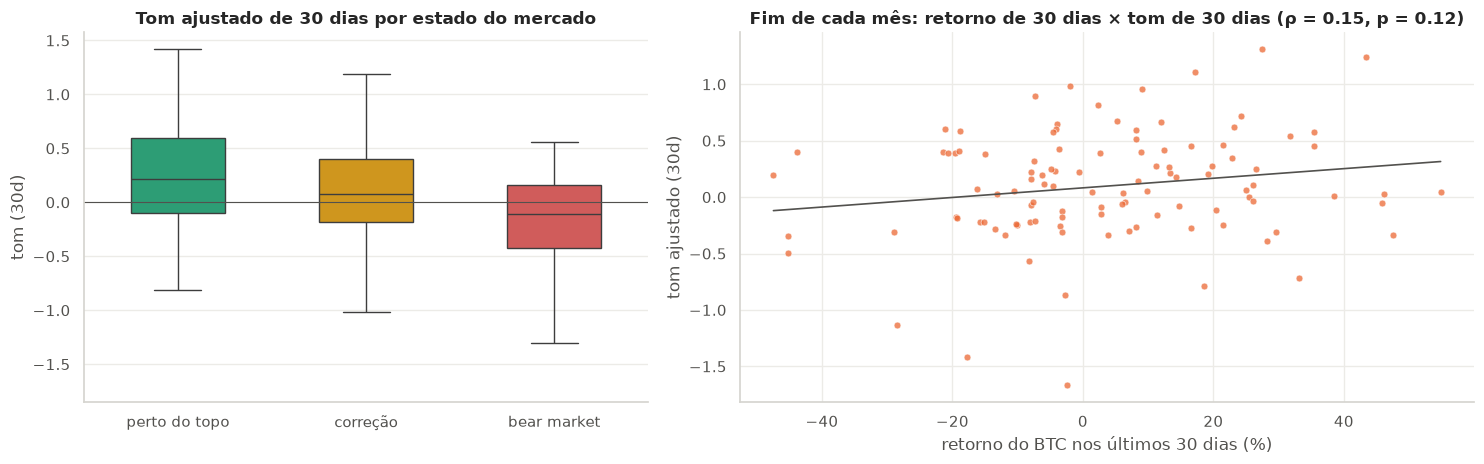

,count,mean,median,std
estado,,,,
perto do topo,1595,0.2601,0.2122,0.4595
correção,933,0.0664,0.0784,0.4049
bear market,728,-0.2155,-0.1040,0.5290


   H0: mesmo tom nos 3 estados
   p-valor = 1.472e-75 -> REJEITA H0 (α = 0.05)

Correlação mensal (n = 107 meses, sem sobreposição):
   H0: ρ(retorno 30d, tom 30d) = 0
   p-valor = 0.1177 -> NÃO rejeita H0 (α = 0.05)


In [28]:
ESTADOS = ["perto do topo", "correção", "bear market"]
estado = pd.cut(data["btc_drawdown_365"], [-np.inf, -0.5, -0.2, np.inf], labels=ESTADOS[::-1])
est = pd.DataFrame({"tom (30d)": data["news_tone_30d"], "estado": estado}).dropna()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1.3]})
sns.boxplot(data=est, x="estado", y="tom (30d)", order=ESTADOS, palette=[C[2], C[3], C[7]], width=0.5,
            fliersize=0, linewidth=1, ax=axes[0])
axes[0].axhline(0, color="#52514e", lw=0.8)
axes[0].set_title("Tom ajustado de 30 dias por estado do mercado")
axes[0].set_xlabel("")

mensal_t = data[["news_tone_30d", "btc_ret_30d"]].resample("ME").last().dropna()
axes[1].scatter(mensal_t["btc_ret_30d"] * 100, mensal_t["news_tone_30d"], s=24, color=C[1], alpha=0.75, edgecolor="white", lw=0.5)
b, a = np.polyfit(mensal_t["btc_ret_30d"] * 100, mensal_t["news_tone_30d"], 1)
xs = np.linspace(mensal_t["btc_ret_30d"].min() * 100, mensal_t["btc_ret_30d"].max() * 100, 50)
axes[1].plot(xs, a + b * xs, color="#52514e", lw=1.2)
rho_m, p_m = stats.spearmanr(mensal_t["btc_ret_30d"], mensal_t["news_tone_30d"])
axes[1].set_title(f"Fim de cada mês: retorno de 30 dias × tom de 30 dias (ρ = {rho_m:.2f}, p = {p_m:.2g})")
axes[1].set_xlabel("retorno do BTC nos últimos 30 dias (%)")
axes[1].set_ylabel("tom ajustado (30d)")
plt.tight_layout()
plt.show()

display(est.groupby("estado", observed=True)["tom (30d)"].agg(["count", "mean", "median", "std"]).loc[ESTADOS])
veredito(stats.kruskal(*[est.loc[est.estado == k, "tom (30d)"] for k in ESTADOS]).pvalue, "mesmo tom nos 3 estados")
print(f"\nCorrelação mensal (n = {len(mensal_t)} meses, sem sobreposição):")
veredito(p_m, "ρ(retorno 30d, tom 30d) = 0")

**Conclusão H12:** o tom acompanha o **estado do mercado**: ele é positivo perto do topo (média de +0,26), neutro nas
correções (+0,07) e negativo nos bear markets (−0,22). O Kruskal-Wallis rejeita H0 com folga, mas o p-valor é otimista
pela persistência das séries. A correlação mensal (sem sobreposição) entre o retorno de 30 dias e o tom de 30 dias é
positiva (ρ ≈ 0,15), mas **não significativa** (p ≈ 0,12, n = 107 meses). O sentimento descreve o **regime** de longo
prazo (o quanto o preço está longe do topo) melhor do que o movimento do último mês. Junto com H7 e H8, o retrato é de
um sentimento que **reflete** o mercado.

## 9. Algum tema específico antecipa o preço? (por cluster)

#### H13. Tom ou volume de algum tema antecipa o BTC?

Talvez o sentimento *agregado* seja reativo, mas notícias de um tema específico (regulação, política monetária,
mineração) carreguem informação nova. Para cada um dos 11 clusters testamos:

- tom do cluster nos últimos 7 dias (*t*) × retorno do BTC em *t + 1* (direção);
- volume anormal de notícias do cluster (*t*) × |retorno| em *t + 1* (volatilidade).

Com 22 testes, os p-valores são corrigidos por **Holm-Bonferroni**.

In [29]:

linhas = []
for c in range(1, N_CLUSTERS + 1):
    for feat, alvo, tipo in [(f"clu{c}_tone_7d", data["target_ret_1d"], "tom → retorno t+1"),
                             (f"clu{c}_count_z30", data["target_absret_1d"], "volume → |retorno| t+1")]:
        rho, p = stats.spearmanr(data[feat], alvo, nan_policy="omit")
        linhas.append({"cluster": c, "tema": nomes[c][:60], "teste": tipo, "rho": rho, "p": p})
res = pd.DataFrame(linhas)
res["p_holm"] = multipletests(res["p"], method="holm")[1]
res["signif. (Holm)"] = res["p_holm"] < ALPHA
with pd.option_context("display.max_colwidth", 70):
    display(res.sort_values("p").round(4))

,cluster,tema,teste,rho,p,p_holm,signif. (Holm)
20,11,York Stock Exchange | New York Stock Exchange,tom → retorno t+1,-0.0593,0.0150,0.3305,False
8,5,EPU_CATS_REGULATION | EPU_POLICY_REGULATORY | LEGISLATION,tom → retorno t+1,-0.0392,0.0259,0.5430,False
9,5,EPU_CATS_REGULATION | EPU_POLICY_REGULATORY | LEGISLATION,volume → |retorno| t+1,0.0245,0.1625,1.0000,False
10,6,WB_696_PUBLIC_SECTOR_MANAGEMENT | WB_831_GOVERNANCE | WB_840,tom → retorno t+1,-0.0220,0.2102,1.0000,False
21,11,York Stock Exchange | New York Stock Exchange,volume → |retorno| t+1,-0.0218,0.2468,1.0000,False
4,3,USPEC_POLICY1 | EPU_ECONOMY_HISTORIC | USPEC_POLITICS_GENERA,tom → retorno t+1,-0.0203,0.2484,1.0000,False
2,2,UNGP_FORESTS_RIVERS_OCEANS | CRISISLEX_CRISISLEXREC | CRISIS,tom → retorno t+1,-0.0162,0.3567,1.0000,False
13,7,WB_1920_FINANCIAL_SECTOR_DEVELOPMENT | EPU_CATS_MONETARY_POL,volume → |retorno| t+1,0.0135,0.4397,1.0000,False
1,1,WB_698_TRADE | TAX_ECON_PRICE | Reuters,volume → |retorno| t+1,0.0135,0.4429,1.0000,False
5,3,USPEC_POLICY1 | EPU_ECONOMY_HISTORIC | USPEC_POLITICS_GENERA,volume → |retorno| t+1,0.0125,0.4765,1.0000,False


**Leitura:** **nenhuma** das 22 relações sobrevive à correção de Holm. Os menores p-valores brutos são do tom do cluster 11
(Bolsa de Nova York) e do cluster 5 (regulação), ambos com ρ entre −0,04 e −0,06, efeitos minúsculos e não significativos
depois da correção. Separar por tema não revela um sinal de direção escondido no agregado.

## 10. Conclusões

**Sobre os dados**
1. **Vazamento corrigido:** as séries macro mensais aparecem na base só depois da data de divulgação (`PUBLICATION_LAGS`
   em `config.py`). A base estruturada (`load_from_hf_struc`) e as notícias (`load_from_hf_nstruc`) são baixadas do
   HuggingFace, e `main.py` reproduz toda a base integrada (3.650 dias × 74 colunas).
2. **Frequências diferentes:** BTC 7 dias por semana, mercados em dias úteis, macro mensal e notícias contínuas
   agregadas por dia UTC. Comparações de retorno com mercados usam só dias úteis, e as séries macro são analisadas
   em frequência mensal.
3. **A cobertura de notícias não é homogênea:** a CoinDesk some por 25 meses (2021–2023), a Reuters some no fim de
   2022 e a Cointelegraph some por 9 meses em 2025, e a composição de fontes muda muito. O volume deve ser usado em
   z-score (relativo ao mês anterior), e o tom, **ajustado pela fonte** (H5), que corta ~80% do efeito da fonte.

**Sobre o Bitcoin (dados estruturados)**

4. **Retorno excepcional com risco extremo:** ~200x em 10 anos, volatilidade de ~68% a.a. (em queda nos últimos anos),
   caudas pesadas e assimetria negativa (H1).
5. **Direção imprevisível, volatilidade previsível (H2):** retornos sem memória, volatilidade em clusters. Com
   **volatilidade menor nos fins de semana** (H3).
6. **Quebra de regime em 2020 (H4):** o BTC passou a se mover com as bolsas (Nasdaq ≈ 0,4) e contra o dólar. Correlações
   em nível com macro são espúrias; em variação, só a Nasdaq importa.

**Sobre as notícias e a pergunta central**

7. **As notícias descrevem o mercado, não o antecipam.** São cinco evidências independentes:
   - as correlações são **contemporâneas** (H6): mesmo dia sim, dia seguinte não;
   - a correlação defasada e a **causalidade de Granger** vão **do preço para a notícia** (H7, H8);
   - no **estudo de eventos**, o CAR fica concentrado **antes** dos choques de tom (≈ +4% antes dos positivos, ≈ −2%
     antes dos negativos) e é nulo depois;
   - o tom acompanha o **estado do mercado** (topo × bear market, H12);
   - **nenhum tema** antecipa o preço depois da correção para múltiplos testes (H13).
8. **Atenção e volatilidade:** o volume de notícias acompanha a volatilidade e o volume negociado **no mesmo dia** e
   salta nos períodos mais turbulentos. Mas os picos de notícias não antecipam movimentos (H9), e, controlando pela
   volatilidade passada, sobra só um efeito pequeno da **% de notícias positivas** e da **dispersão do tom** sobre a
   volatilidade da semana seguinte (H10, |ρ| < 0,10).
9. **Estabilidade:** a relação entre notícias e preço não mudou significativamente em 2020 (H11). O fraco poder
   preditivo da atenção que existia em 2017–2019 desapareceu.
10. **As notícias não capturam o risco global:** praticamente não há correlação entre as notícias e os retornos de
    Nasdaq/DXY, justamente o canal que mais explica o BTC desde 2020.

**Implicações para a modelagem**

- **Direção:** a expectativa é que as features do GDELT diário contribuam pouco. Isso é testado fora da amostra com uma
  ablação no `modeling_baseline.ipynb` (H15).
- **Volatilidade:** usar o HAR (volatilidade passada) como base e testar a **% positiva** e a **dispersão do tom** como
  variáveis exógenas (H14), já que o volume de notícias sozinho não acrescenta nada.
- **Cuidados:** validação temporal (walk-forward) por causa da quebra de 2020; controle de fim de semana; volume de
  notícias em z-score por causa dos buracos de cobertura.
- **Para extrair sinal de direção**, as notícias precisariam ser **mais rápidas e mais específicas**: granularidade
  horária (o GDELT tem resolução de 15 min), eventos agendados (decisões do Fed, aprovação de ETFs) ou fontes que
  antecedem o mercado (redes sociais). Ficam como próximos passos.